# Approve, Refer or Decline? A profit-optimal credit policy

**The question.** A consumer lender approves every application its current process passes. Some of
those loans lose money. Which applicants should it **approve**, which should go to an **underwriter**,
and which should it **decline** to make the most profit, with a reason it can give to every declined
customer?

**The data.** 789,144 real loans from Bondora / Go & Grow (Estonia, Finland, Netherlands, Latvia,
Denmark), issued 2009 → Jun 2026, including the cash each loan actually repaid. Modelling uses the
244k loans issued Oct 2023 – Jun 2025 that have a 12-month outcome. The 185k loans issued since then
are the live population for drift monitoring.

**What I found**

| | |
|---|---|
| **The leak** | 20 of 31 columns are recorded *after* the loan is issued. Including just four of them gives a fake AUC of **0.995**. The honest ceiling is ≈ 0.73. |
| **The economics** | Measured from cash: a loan that performs for 12 months returns **+21 %** of principal over its life; a 12-month default loses **−57 %**. Break-even default risk ranges from **6 % to 23 %** depending on the term. |
| **The pricing gap** | Grades AA to F all pay ≈ 18 % APR, while 12-month default risk rises from 3 % to 19 %. When price doesn't absorb risk, the approval decision has to. |
| **The model** | A monotone WoE **scorecard beats gradient boosting out-of-time** (AUC 0.730 vs 0.721, the gap is significant), is well calibrated (ECE 0.6 pp), and gives exact reason codes. Champion: scorecard. |
| **The policy** | On 81k unseen 2025 loans (€155M lent), realised profit rises from **€2.0M → €4.7M (+€2.7M)**: approve 70 %, refer 8 % (large, borderline loans), decline 22 %. The bad rate of approved loans falls from 8.1 % to **4.7 %**. |
| **Robustness** | The optimum is a broad plateau (67–78 % approval). Only the **cost of funds** materially moves the answer. In a downturn (PDs × 1.5) the policy is worth **€5.1M** while approving everyone *loses* money. |
| **Watch-outs** | Product mix shifted hard to 84–120-month terms (PSI > 0.25), and Denmark is a new market the model under-predicts (25 % vs 39 %). Both have a concrete mitigation below. |

> Notebook outputs are saved. Every number in this summary is produced by the cells below.

## 0 · Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import credit as cr

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40, "display.width", 200)
FIG, ART, REP, DATA = (ROOT / p for p in ("figures", "artifacts", "reports", "data"))
for p in (FIG, ART, REP):
    p.mkdir(exist_ok=True)

# One visual language for every chart: validated categorical palette,
# ink-coloured text, recessive grid, no top/right spines.
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", violet="#4a3aa7", red="#e34948", green="#008300",
         ink="#0b0b0b", ink2="#52514e", muted="#8a8984", grid="#e7e6e2", surface="#ffffff")
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 12.5, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelsize": 10, "xtick.color": C["ink2"], "ytick.color": C["ink2"], "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": C["grid"],
    "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 9,
    "font.family": "DejaVu Sans", "lines.linewidth": 2, "figure.dpi": 110,
})

def save(fig, name, note=None):
    if note:
        fig.text(0.0, -0.02, note, fontsize=8.5, color=C["ink2"], ha="left", va="top", transform=fig.transFigure)
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def eur(x, pos=None):
    a = abs(x)
    s = f"€{a/1e6:.1f}M" if a >= 1e6 else (f"€{a/1e3:.0f}k" if a >= 1e3 else f"€{a:.0f}")
    return ("−" if x < 0 else "") + s

pct = mtick.PercentFormatter(1.0, decimals=0)
RNG = np.random.default_rng(42)
print("project root:", ROOT)

project root: /home/claude/credit-policy


## 1 · The data: 17 years of real consumer loans

The source is the public loan-level dataset of **Bondora / Go & Grow**, an Estonian consumer lender
operating in Finland, Estonia, the Netherlands, Latvia and Denmark. The file was downloaded on
1 Oct 2026 and contains **every loan issued from Feb 2009 to Jun 2026**, together with what happened
to it afterwards: payments received, defaults and write-offs.

That last part matters. Most public credit datasets give you a default flag and nothing else, so
"profit" ends up as a made-up number. Here we can measure **euros actually repaid**.

In [2]:
raw_path = DATA / "raw_loans.pkl"
if raw_path.exists():
    raw = pd.read_pickle(raw_path)
else:  # first run: convert the Excel download once (~2 min)
    raw = pd.read_excel(ROOT / "loan_dataset_investor.xlsx", sheet_name="Loan Dataset")
    raw.to_pickle(raw_path)
raw["issued_at"] = pd.to_datetime(raw["loan_issued_at"], format="mixed")
print(f"{len(raw):,} loans × {raw.shape[1]-1} columns | issued {raw.issued_at.min():%b %Y} → {raw.issued_at.max():%b %Y}")
print(f"latest recorded loan event: {pd.to_datetime(raw.loan_last_recorded_action_date_local, format='mixed').max():%d %b %Y}")

789,144 loans × 31 columns | issued Feb 2009 → Jun 2026
latest recorded loan event: 20 Jul 2026


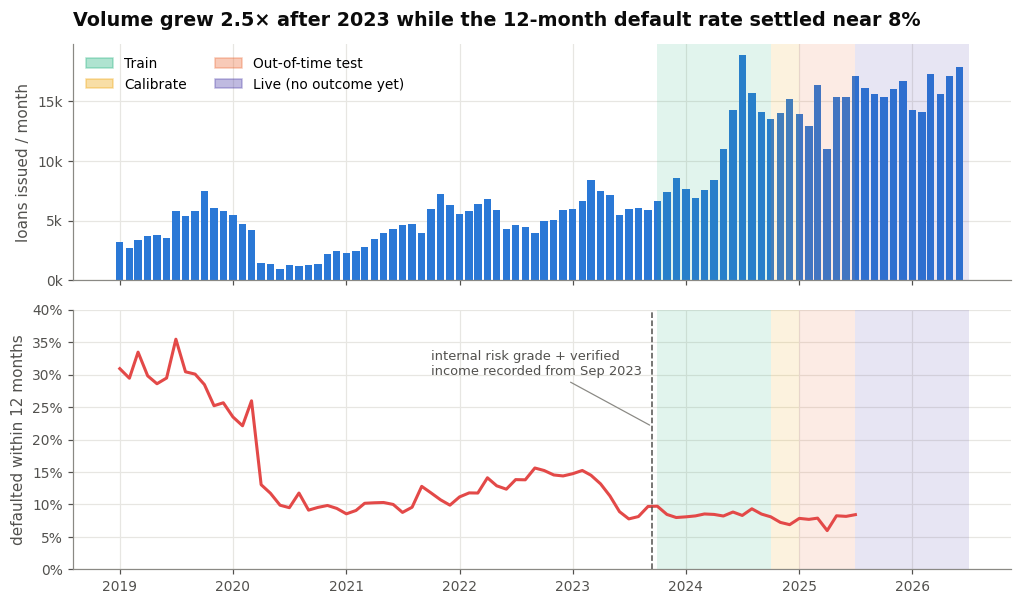

In [3]:
m = raw.assign(month=raw.issued_at.dt.to_period("M").dt.to_timestamp()).groupby("month").agg(
    loans=("loan_id", "size"),
    dr12=("has_default_within_12_months", "mean"),
    graded=("customer_risk_rating", lambda s: s.notna().mean()),
)
m = m[m.index >= "2019-01-01"]
WIN = dict(train=("2023-10-01", "2024-10-01"), valid=("2024-10-01", "2025-01-01"),
           test=("2025-01-01", "2025-07-01"), live=("2025-07-01", "2026-07-01"))

from matplotlib.patches import Patch
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.1], hspace=0.12))
a1.bar(m.index, m.loans, width=24, color=C["blue"])
a1.yaxis.set_major_locator(mtick.MultipleLocator(5000))
a1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, p: f"{x/1e3:.0f}k"))
a1.set_ylabel("loans issued / month")
a1.set_title("Volume grew 2.5× after 2023 while the 12-month default rate settled near 8%")
a2.plot(m.index, m.dr12, color=C["red"])
a2.yaxis.set_major_formatter(pct)
a2.set_ylabel("defaulted within 12 months")
a2.set_ylim(0, .4)
spans = [("train", C["aqua"], "Train"), ("valid", C["yellow"], "Calibrate"),
         ("test", C["orange"], "Out-of-time test"), ("live", C["violet"], "Live (no outcome yet)")]
for ax in (a1, a2):
    for k, col, lab in spans:
        ax.axvspan(pd.Timestamp(WIN[k][0]), pd.Timestamp(WIN[k][1]), color=col, alpha=.13, lw=0)
a1.legend(handles=[Patch(color=col, alpha=.35, label=lab) for _, col, lab in spans], loc="upper left", ncol=2)
a2.axvline(pd.Timestamp("2023-09-15"), color=C["ink2"], lw=1, ls="--")
a2.annotate("internal risk grade + verified\nincome recorded from Sep 2023", xy=(pd.Timestamp("2023-09-15"), .22),
            xytext=(pd.Timestamp("2021-10-01"), .30), fontsize=8.5, color=C["ink2"],
            arrowprops=dict(arrowstyle="-", color=C["muted"], lw=.8))
save(fig, "01_book_and_windows")
plt.show()

**Reading the chart.** Two facts shape every design decision that follows:

1. The lender's **internal risk grade and verified income only exist from Sep 2023**. Before that, the
   data has no applicant information worth modelling. So the modelling window starts in **Oct 2023**.
2. The target, *default within 12 months on book*, can only be observed for loans that are at least
   12 months old. Loans issued after Jun 2025 have no outcome yet. They are not wasted: they are the
   **live population** for the drift check in §11.

Time-based split, so the model is always tested on loans issued *after* the ones it learned from:

| Window | Issued | Role |
|---|---|---|
| Train | Oct 2023 – Sep 2024 | fit binning, scorecard and gradient boosting |
| Calibrate | Oct – Dec 2024 | early stopping, probability calibration, choosing the policy |
| Out-of-time test | Jan – Jun 2025 | the only numbers reported as performance |
| Live | Jul 2025 – Jun 2026 | no labels yet: drift monitoring |

## 2 · Leakage log: 31 columns, 7 usable

Before any modelling, every column gets one question: **would this value exist at the moment the
credit decision is made?** In a servicing extract like this one most columns are *outcomes in
disguise*: payments received, days past due, months in default. A model trained on them would look
brilliant and be worthless in production.

In [4]:
LOG = [
 # column, role, available_at_decision, verdict, why
 ("loan_id", "identifier", "yes", "drop", "Random key, no information"),
 ("loan_issued_at", "timestamp", "yes", "use (split + hour)", "Defines cohorts; hour of application is a legitimate signal"),
 ("country", "application", "yes", "use", "Market of the borrower"),
 ("issued_amount", "application", "yes", "use", "Requested and approved amount"),
 ("initial_loan_duration", "application", "yes", "use", "Requested term"),
 ("initial_interest_rate", "application", "yes", "use", "Price offered at decision time"),
 ("combined_income", "application", "yes", "use", "Income verified from bank statements and registry at application"),
 ("customer_risk_rating", "application", "yes", "use", "Internal grade at time of issue (per data dictionary)"),
 ("projected_npv_return", "model output", "unclear", "exclude", "Output of the incumbent pricing engine; refresh timing undocumented, so excluded by default (ablation below)"),
 ("has_default_within_12_months", "target", "no", "TARGET", "Default observed within 12 months on book"),
 ("is_default", "outcome", "no", "LEAK", "Current default flag, known only after the fact"),
 ("loan_status", "outcome", "no", "LEAK", "Repaid / Defaulted / Active as of the snapshot"),
 ("loan_status_risk", "outcome", "no", "LEAK (used for exclusions)", "Snapshot status incl. Written Off / Cancelled"),
 ("months_in_default", "outcome", "no", "LEAK", "Exists only for defaulted loans"),
 ("days_past_due_principal", "outcome", "no", "LEAK", "Arrears after issue"),
 ("debt_occured_date_local", "outcome", "no", "LEAK", "Date arrears began"),
 ("principal_debt", "outcome", "no", "LEAK", "Unpaid scheduled principal"),
 ("principal_balance", "outcome", "no", "LEAK", "Outstanding balance at snapshot"),
 ("principal_paid_total", "outcome", "no", "LEAK (economics only)", "Cash received; used to measure profit, never as a feature"),
 ("interest_paid_total", "outcome", "no", "LEAK (economics only)", "Cash received"),
 ("extra_interest_paid_total", "outcome", "no", "LEAK", "Penalty interest paid, only after a missed payment"),
 ("late_fee_paid_total", "outcome", "no", "LEAK (economics only)", "Only after a missed payment"),
 ("maintenance_fee_paid_total", "outcome", "no", "LEAK (economics only)", "Accrues with time on book"),
 ("repaid_amount_total", "outcome", "no", "LEAK (economics only)", "Total cash repaid to date"),
 ("months_on_book", "outcome", "no", "LEAK", "Short for loans that default early: a direct proxy of the target"),
 ("nr_of_payments", "outcome", "no", "LEAK", "Payment counter at snapshot"),
 ("next_payment_nr", "outcome", "no", "LEAK", "0 when the loan is closed or defaulted"),
 ("next_payment_date_local", "outcome", "no", "LEAK", "Missing when the loan is closed or defaulted"),
 ("early_repaid_at", "outcome", "no", "LEAK", "Prepayment date"),
 ("is_early_repaid_within_14_days", "outcome", "no", "exclusion rule", "14-day cooling-off withdrawals are not credit decisions"),
 ("loan_last_recorded_action_date_local", "outcome", "no", "LEAK", "Last servicing event"),
]
leak_log = pd.DataFrame(LOG, columns=["column", "role", "known_at_decision", "verdict", "rationale"])
assert set(leak_log.column) == set(raw.columns) - {"issued_at"}, set(raw.columns) ^ set(leak_log.column)
leak_log.to_csv(REP / "leakage_log.csv", index=False)
print(leak_log.verdict.str.split(" ").str[0].value_counts().to_string())
leak_log

verdict
LEAK         20
use           7
drop          1
exclude       1
TARGET        1
exclusion     1


,column,role,known_at_decision,verdict,rationale
0,loan_id,identifier,yes,drop,"Random key, no information"
1,loan_issued_at,timestamp,yes,use (split + hour),Defines cohorts; hour of application is a legitimate signal
2,country,application,yes,use,Market of the borrower
3,issued_amount,application,yes,use,Requested and approved amount
4,initial_loan_duration,application,yes,use,Requested term
5,initial_interest_rate,application,yes,use,Price offered at decision time
6,combined_income,application,yes,use,Income verified from bank statements and registry at application
7,customer_risk_rating,application,yes,use,Internal grade at time of issue (per data dictionary)
8,projected_npv_return,model output,unclear,exclude,"Output of the incumbent pricing engine; refresh timing undocumented, so excluded by default (ablation below)"
9,has_default_within_12_months,target,no,TARGET,Default observed within 12 months on book


**Proving the leak is real.** The check below fits the same gradient boosting model twice on the same
training window: once with honest features, once with four "innocent-looking" servicing columns
added. The leaky model scores a near-perfect AUC on the test window. That is the number a careless
notebook would put on a slide.

In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

def in_win(d, k):
    return (d.issued_at >= WIN[k][0]) & (d.issued_at < WIN[k][1])

_d = raw[(in_win(raw, "train") | in_win(raw, "test")) & raw.has_default_within_12_months.notna()
         & raw.customer_risk_rating.notna() & (raw.loan_status_risk != "Cancelled")].copy()
_d["rating_rank"] = _d.customer_risk_rating.map({g: i for i, g in enumerate(cr.RATING_ORDER)})
honest = ["rating_rank", "combined_income", "issued_amount", "initial_interest_rate", "initial_loan_duration"]
leaky = honest + ["months_on_book", "interest_paid_total", "maintenance_fee_paid_total", "nr_of_payments"]
res = []
for name, cols in [("honest (5 application fields)", honest), ("+ 4 servicing columns", leaky),
                   ("honest + projected_npv_return", honest + ["projected_npv_return"])]:
    tr, te = in_win(_d, "train"), in_win(_d, "test")
    mdl = HistGradientBoostingClassifier(max_iter=200, random_state=0).fit(_d.loc[tr, cols], _d.loc[tr, "has_default_within_12_months"])
    auc = roc_auc_score(_d.loc[te, "has_default_within_12_months"], mdl.predict_proba(_d.loc[te, cols])[:, 1])
    res.append((name, auc))
leak_demo = pd.DataFrame(res, columns=["feature set", "test AUC"]).set_index("feature set").round(3)
leak_demo

,test AUC
feature set,
honest (5 application fields),0.685
+ 4 servicing columns,0.995
honest + projected_npv_return,0.653


Four servicing columns turn a realistic **0.685** AUC into a fake **0.995**. `months_on_book` alone gives
the game away: a loan that defaults early simply has fewer months on book.

`projected_npv_return` is the hard case. It *might* be fixed at issuance, but the dictionary does not
say so, and it is the output of the lender's own pricing model. Excluding it costs nothing: adding it
actually *lowers* the out-of-time AUC (0.653), a sign that it encodes something that does not
generalise. **Rule applied: if the timestamp of a field cannot be proven, it stays out.** The full log
with a rationale per column is saved to `reports/leakage_log.csv`.

## 3 · Sample design

The rule for each exclusion is that it must be something a lender could also apply **on the day of
the decision**. Otherwise it would create a sample the production policy never sees.

In [6]:
steps = []
d = raw.copy()
steps.append(("All loans in the file", len(d)))
d = d[d.issued_at >= WIN["train"][0]]; steps.append(("Issued Oct 2023 or later (grade + income recorded)", len(d)))
d = d[d.loan_status_risk != "Cancelled"]; steps.append(("Exclude 14-day cooling-off withdrawals", len(d)))
d = d[d.customer_risk_rating.notna()]; steps.append(("Exclude loans without a risk grade", len(d)))
d = d[d.customer_risk_rating != "HR"]; steps.append(("Exclude 'HR' grade (n≈40, legacy code)", len(d)))
live = d[in_win(d, "live")].copy()
d = d[d.issued_at < WIN["test"][1]]
steps.append(("Loans with a 12-month outcome (issued ≤ Jun 2025)", len(d)))
assert d.has_default_within_12_months.notna().all()
d["y"] = d.has_default_within_12_months.astype(int)
waterfall = pd.DataFrame(steps, columns=["step", "loans"])
waterfall["removed"] = (-waterfall.loans.diff()).fillna(0).astype(int)
print(waterfall.to_string(index=False))
print(f"\nlive population (Jul 2025 – Jun 2026, no outcome yet): {len(live):,}")

                                              step  loans  removed
                             All loans in the file 789144        0
Issued Oct 2023 or later (grade + income recorded) 448271   340873
            Exclude 14-day cooling-off withdrawals 428944    19327
                Exclude loans without a risk grade 428817      127
            Exclude 'HR' grade (n≈40, legacy code) 428775       42
 Loans with a 12-month outcome (issued ≤ Jun 2025) 244267   184508

live population (Jul 2025 – Jun 2026, no outcome yet): 184,508


**A limitation stated up front: this is a book of *approved* loans.** Applicants the lender rejected
are not in the data, so nobody can know how they would have performed. The honest framing is
therefore: *given the applications the current process lets through, which ones should a
profit-maximising policy approve, send to an underwriter, or decline?* The policy can tighten the
current one, but it cannot justify loosening it. Expanding approval would need reject inference or a
small randomised test-and-learn budget (see §13).

## 4 · What a loan is worth: unit economics from cash actually received

A credit policy is a bet: every approval earns a margin if the loan performs and loses part of the
principal if it does not. Instead of assuming those numbers, they are **measured from the 2021–2022
cohorts**. Those loans have had 3.5–5 years to show their real cash outcome, and the pricing then
(≈ 17–19 % APR) was close to today's.

For each loan: `net cash return = (all cash repaid + late fees + any still-performing balance − amount lent) / amount lent`,
split by whether the loan defaulted within 12 months. This is the same label the model predicts. A
loan that is "good at 12 months" can still default later, so its return already includes those
later losses. This keeps the 12-month model consistent with lifetime money.

Exposure (`principal-years`) is recovered as `interest paid ÷ interest rate`. It is used to charge a
cost of funds.

In [7]:
o = raw[(raw.issued_at.dt.year.isin([2021, 2022])) & (raw.loan_status_risk != "Cancelled")
        & raw.has_default_within_12_months.notna()].copy()
o["cash"] = o.repaid_amount_total.fillna(0) + o.late_fee_paid_total.fillna(0)
o["open_balance"] = np.where(o.loan_status == "Active", o.principal_balance.fillna(0), 0)
o["net"] = (o.cash + o.open_balance - o.issued_amount) / o.issued_amount
o["py"] = o.interest_paid_total / o.initial_interest_rate / o.issued_amount
o["term_bucket"] = cr.term_bucket(o.initial_loan_duration)
o["bad"] = o.has_default_within_12_months.astype(int)
g = o.groupby(["term_bucket", "bad"]).agg(n=("loan_id", "size"), net=("net", "mean"), py=("py", "mean"),
                                         eur_lent=("issued_amount", "sum")).unstack("bad")
econ = pd.DataFrame({
    "loans": g[("n", 0)] + g[("n", 1)],
    "default_rate_12m": g[("n", 1)] / (g[("n", 0)] + g[("n", 1)]),
    "net_good": g[("net", 0)], "py_good": g[("py", 0)],
    "net_bad": g[("net", 1)], "py_bad": g[("py", 1)],
}).reindex(cr.TERM_LABELS)
econ.to_csv(ART / "unit_economics_raw.csv")
econ.style.format({"loans": "{:,.0f}", "default_rate_12m": "{:.1%}", "net_good": "{:+.1%}", "net_bad": "{:+.1%}",
                   "py_good": "{:.2f}", "py_bad": "{:.2f}"})

,loans,default_rate_12m,net_good,py_good,net_bad,py_bad
term_bucket,,,,,,
<=12m,"7,911",4.7%,+8.5%,0.51,-40.8%,0.19
13-24m,"6,577",6.7%,+18.5%,1.08,-50.8%,0.25
25-36m,"5,529",10.3%,+24.5%,1.41,-56.5%,0.25
37-48m,"2,739",9.5%,+29.6%,1.70,-49.7%,0.29
49-60m,"86,035",13.6%,+21.9%,1.82,-58.7%,0.27
>60m,"2,782",16.2%,+21.5%,2.13,-57.4%,0.27


In [8]:
cohort_check = o.groupby([o.issued_at.dt.year.rename("cohort"), "bad"]).net.mean().unstack().rename(
    columns={0: "return if good @12m", 1: "return if default @12m"})
cohort_check.style.format("{:+.1%}")

bad,return if good @12m,return if default @12m
cohort,,
2021,+20.9%,-55.7%
2022,+21.0%,-58.9%


The two cohorts agree to within one or two percentage points: **a performing loan returns about
+21 % of principal in cash, and a 12-month default loses about −57 %**, even after collections. Those
two numbers, less funding and operating costs, are the whole business case:

In [9]:
PARAMS = dict(cr.DEFAULT_PARAMS)
ue = cr.unit_economics(econ, PARAMS)
ue[["gain", "loss", "breakeven_pd"]].style.format({"gain": "{:+.1%}", "loss": "{:.1%}", "breakeven_pd": "{:.1%}"})

,gain,loss,breakeven_pd
term_bucket,,,
<=12m,+3.4%,49.9%,6.4%
13-24m,+10.0%,60.3%,14.3%
25-36m,+14.1%,66.0%,17.5%
37-48m,+17.4%,59.4%,22.7%
49-60m,+8.9%,68.3%,11.6%
>60m,+6.7%,67.0%,9.1%


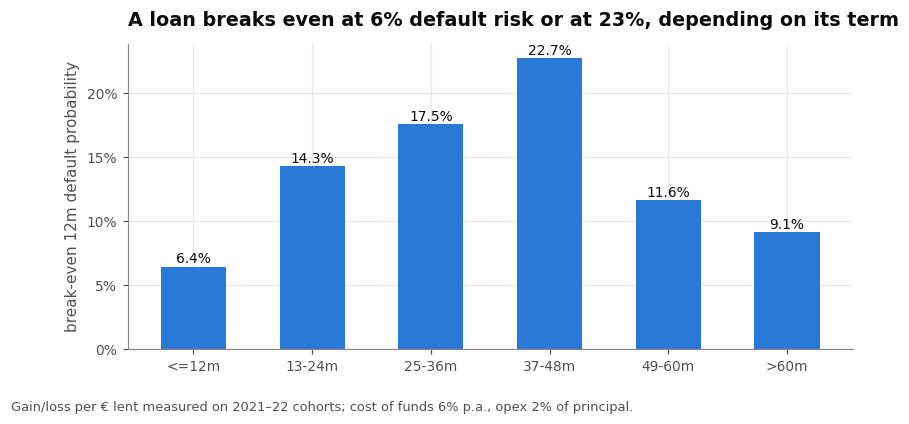

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(len(ue))
ax.bar(x, ue.breakeven_pd, width=.55, color=C["blue"])
for i, v in enumerate(ue.breakeven_pd):
    ax.text(i, v + .003, f"{v:.1%}", ha="center", fontsize=9, color=C["ink"])
ax.set_xticks(x, ue.index)
ax.yaxis.set_major_formatter(pct)
ax.set_ylabel("break-even 12m default probability")
ax.set_title("A loan breaks even at 6% default risk or at 23%, depending on its term")
save(fig, "02_breakeven_by_term",
     note=f"Gain/loss per € lent measured on 2021–22 cohorts; cost of funds {PARAMS['cost_of_funds']:.0%} p.a., opex {PARAMS['opex']:.0%} of principal.")
plt.show()

**Why this matters for the policy.** Break-even is `gain ÷ (gain + loss)`. A 12-month loan earns so
little interest that it stops paying at a 6 % default risk, while a 3–4-year loan can absorb more than
20 %. The common 5-year loans sit in between: they earn for longer, but they also tie up funding for
longer and suffer more late defaults. **One score cut-off cannot be profit-optimal across terms.** The final policy
therefore decides on *expected euros per application*, not on a score alone (§8).

## 5 · Features: what the lender knows at the moment of decision

Seven raw application fields become eleven candidate features. The derived ones are standard
affordability measures that underwriters actually use:

* `monthly_instalment`: annuity payment implied by amount, rate and term
* `payment_to_income`: instalment ÷ verified monthly income (the classic PTI ratio)
* `loan_to_income`: amount ÷ monthly income
* `price_premium`: how far the offered rate sits above the typical rate for the same grade and term
  (the reference medians are learned on the training window only)
* `application_hour`: hour of the day the loan was taken

In [11]:
train_mask, valid_mask, test_mask = (in_win(d, k) for k in ("train", "valid", "test"))
price_ref = cr.add_features(d[train_mask]).groupby(["customer_risk_rating", "term_bucket"], observed=True)["initial_interest_rate"].median()
d = cr.add_features(d, price_ref)
live = cr.add_features(live, price_ref)
tr, va, te = d[train_mask].copy(), d[valid_mask].copy(), d[test_mask].copy()
for n_, x_ in [("train", tr), ("calibrate", va), ("test", te), ("live", live)]:
    print(f"{n_:>10}: {len(x_):>7,} loans | 12m default rate "
          + (f"{x_.y.mean():.2%}" if "y" in x_ and x_.y.notna().any() else "  n/a "))
NUM = ["rating_rank", "combined_income", "issued_amount", "initial_loan_duration", "initial_interest_rate",
       "monthly_instalment", "payment_to_income", "loan_to_income", "price_premium", "application_hour"]
CAT = ["country"]
FEATURES = NUM + CAT

     train: 121,684 loans | 12m default rate 8.95%
 calibrate:  41,119 loans | 12m default rate 7.69%
      test:  81,464 loans | 12m default rate 8.06%
      live: 184,508 loans | 12m default rate   n/a 


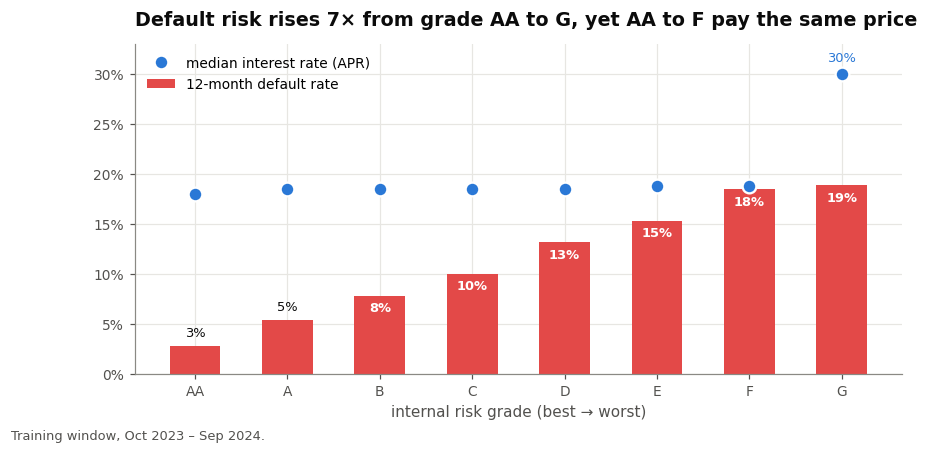

,loans,default_rate,median_rate
customer_risk_rating,,,
AA,"21,648",2.8%,18.1%
A,"18,340",5.4%,18.5%
B,"24,199",7.8%,18.5%
C,"25,856",10.0%,18.5%
D,"14,779",13.2%,18.5%
E,"8,702",15.3%,18.8%
F,"5,867",18.5%,18.8%
G,"2,293",18.9%,30.0%


In [12]:
gr = tr.groupby("customer_risk_rating", observed=True).agg(loans=("y", "size"), default_rate=("y", "mean"),
                                                            median_rate=("initial_interest_rate", "median")).reindex(cr.RATING_ORDER[:-1])
fig, ax = plt.subplots(figsize=(9, 3.9))
x = np.arange(len(gr))
ax.bar(x, gr.default_rate, width=.55, color=C["red"], label="12-month default rate")
ax.plot(x, gr.median_rate, "o", color=C["blue"], ms=9, mec="white", mew=1.5, label="median interest rate (APR)")
for i, (dr_, r_) in enumerate(zip(gr.default_rate, gr.median_rate)):
    inside = dr_ > .06
    ax.text(i, dr_ - .006 if inside else dr_ + .006, f"{dr_:.0%}", ha="center", va="top" if inside else "bottom",
            fontsize=8.5, color="white" if inside else C["ink"], fontweight="semibold" if inside else "normal")
ax.set_xticks(x, gr.index)
ax.set_xlabel("internal risk grade (best → worst)")
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, .33)
ax.legend(loc="upper left")
ax.text(len(gr) - 1, gr.median_rate.iloc[-1] + .012, f"{gr.median_rate.iloc[-1]:.0%}", ha="center", fontsize=8.5, color=C["blue"])
ax.set_title("Default risk rises 7× from grade AA to G, yet AA to F pay the same price")
save(fig, "03_risk_vs_price_by_grade", note="Training window, Oct 2023 – Sep 2024.")
plt.show()
gr.style.format({"loans": "{:,.0f}", "default_rate": "{:.1%}", "median_rate": "{:.1%}"})

**This chart is the business case for the project.** The incumbent prices almost every grade at about
17–19 %, so a grade-G borrower pays about the same as a grade-AA borrower while defaulting about 7×
as often. When price does not absorb risk, **the approval decision has to.** At an expected 12-month
default rate of about 20 %, a typical loan in the weakest grades loses money on every euro lent (see
the break-even table in §4).

## 6 · Model A: a monotone WoE scorecard

The benchmark is the model regulators, auditors and credit committees already understand. Each
feature is binned into 4–20 groups, adjacent groups are merged until the bad rate moves in one
direction only (no "U-shapes" that would be hard to defend in an adverse-action letter), each group
is replaced by its Weight of Evidence, and a logistic regression turns the WoE values into points.
`application_hour` is the one feature allowed to be non-monotone, since time of day has no natural
direction.

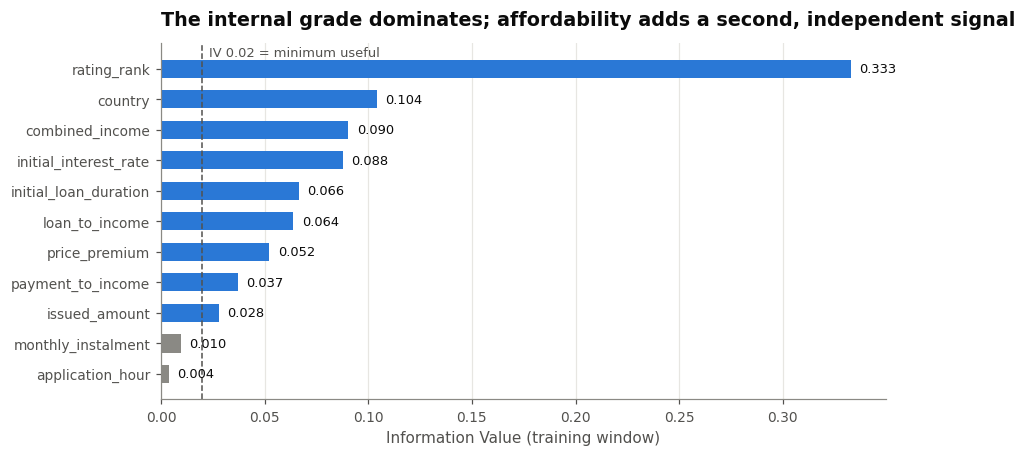

In [13]:
binners = {}
for f in NUM:
    binners[f] = cr.Binner(f, monotone=(f != "application_hour")).fit(tr[f], tr.y)
for f in CAT:
    binners[f] = cr.Binner(f, kind="categorical").fit(tr[f], tr.y)
iv = pd.Series({f: b.iv_ for f, b in binners.items()}).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 4.2))
cols = [C["blue"] if v >= .02 else C["muted"] for v in iv]
ax.barh(iv.index, iv.values, color=cols, height=.6)
for i, v in enumerate(iv.values):
    ax.text(v + .004, i, f"{v:.3f}", va="center", fontsize=8.5, color=C["ink"])
ax.axvline(.02, color=C["ink2"], lw=1, ls="--")
ax.text(.023, len(iv) - .6, "IV 0.02 = minimum useful", fontsize=8.5, color=C["ink2"])
ax.set_xlabel("Information Value (training window)")
ax.set_title("The internal grade dominates; affordability adds a second, independent signal")
ax.grid(axis="y", visible=False)
save(fig, "04_information_value")
plt.show()

**Feature selection for the scorecard** follows three rules: (1) IV ≥ 0.02; (2) when two WoE
features are more than 0.6 correlated, keep the stronger one, because collinear features produce
unstable and sometimes wrong-signed points; (3) every coefficient must have the expected sign. A
scorecard where a *better* attribute earns *fewer* points cannot be signed off.

In [14]:
cand = [f for f in iv.sort_values(ascending=False).index if iv[f] >= .02]
Wtr = pd.DataFrame({f: binners[f].transform(tr[f]) for f in cand})
corr = Wtr.corr().abs()
selected = []
for f in cand:
    if all(corr.loc[f, s] <= .6 for s in selected):
        selected.append(f)
dropped_corr = [f for f in cand if f not in selected]
while True:
    sc = cr.Scorecard().fit(tr, tr.y, {f: binners[f] for f in selected})
    pos = [f for f, b in zip(sc.features, sc.lr.coef_[0]) if b > 0]
    if not pos:
        break
    selected.remove(pos[0])
print("candidates (IV≥0.02):", cand)
print("dropped for collinearity:", dropped_corr)
print("final scorecard features:", sc.features)
print("coefficients:", dict(zip(sc.features, sc.lr.coef_[0].round(3))))
display(corr.round(2))

candidates (IV≥0.02): ['rating_rank', 'country', 'combined_income', 'initial_interest_rate', 'initial_loan_duration', 'loan_to_income', 'price_premium', 'payment_to_income', 'issued_amount']
dropped for collinearity: ['initial_interest_rate', 'payment_to_income', 'issued_amount']
final scorecard features: ['rating_rank', 'country', 'combined_income', 'initial_loan_duration', 'loan_to_income']
coefficients: {'rating_rank': np.float64(-0.905), 'country': np.float64(-0.677), 'combined_income': np.float64(-0.2), 'initial_loan_duration': np.float64(-0.918), 'loan_to_income': np.float64(-0.65)}


,rating_rank,country,combined_income,initial_interest_rate,initial_loan_duration,loan_to_income,price_premium,payment_to_income,issued_amount
rating_rank,1,0.13,0.18,0.25,0.03,0.06,0.21,0.06,0.02
country,0.13,1,0.41,0.64,0.07,0.06,0.55,0.15,0.05
combined_income,0.18,0.41,1,0.49,0.03,0.28,0.41,0.34,0.03
initial_interest_rate,0.25,0.64,0.49,1,0.02,0.09,0.84,0.17,0.05
initial_loan_duration,0.03,0.07,0.03,0.02,1,0.22,0,0.13,0.23
loan_to_income,0.06,0.06,0.28,0.09,0.22,1,0.09,0.88,0.82
price_premium,0.21,0.55,0.41,0.84,0,0.09,1,0.16,0.02
payment_to_income,0.06,0.15,0.34,0.17,0.13,0.88,0.16,1,0.71
issued_amount,0.02,0.05,0.03,0.05,0.23,0.82,0.02,0.71,1


In [15]:
sc_table = sc.table.copy()
sc_table["attribute"] = sc_table.attribute.astype(str)
sc_table.to_csv(ART / "scorecard_points.csv", index=False)
card = cr.export_card(sc)
json.dump(card, open(ART / "scorecard.json", "w"), indent=1)
# parity test: the JSON card must reproduce the in-memory scorecard exactly
_chk = va.sample(2000, random_state=1)
_json_scores = _chk.apply(lambda r: sum(cr.card_points(card, r[sc.features].to_dict()).values()), axis=1)
assert (_json_scores.values == sc.score(_chk).values).all(), "JSON scorecard does not match"
print("JSON scorecard reproduces the fitted scorecard on 2,000 held-out applicants ✓")
pts_range = sc_table.groupby("feature").points.agg(["min", "max"])
pts_range["spread"] = pts_range["max"] - pts_range["min"]
print(f"score range: {pts_range['min'].sum()} – {pts_range['max'].sum()} points "
      f"(600 = 50:1 good:bad odds, +20 points doubles the odds)\n")
print(pts_range.sort_values("spread", ascending=False).to_string())
(sc_table[sc_table.feature.isin(["rating_rank", "payment_to_income"])]
   [["feature", "attribute", "share", "bad_rate", "woe", "points"]]
   .style.format({"share": "{:.1%}", "bad_rate": "{:.1%}", "woe": "{:+.2f}"}).hide(axis="index"))

JSON scorecard reproduces the fitted scorecard on 2,000 held-out applicants ✓
score range: 485 – 624 points (600 = 50:1 good:bad odds, +20 points doubles the odds)

                       min  max  spread
feature                                
rating_rank             89  142      53
country                 79  122      43
initial_loan_duration  107  129      22
loan_to_income         103  118      15
combined_income        107  113       6


feature,attribute,share,bad_rate,woe,points
rating_rank,"(-inf, 0.0]",17.8%,2.8%,+1.21,142
rating_rank,"(0.0, 1.0]",15.1%,5.4%,+0.54,125
rating_rank,"(1.0, 2.0]",19.9%,7.8%,+0.15,115
rating_rank,"(2.0, 3.0]",21.2%,10.0%,-0.12,108
rating_rank,"(3.0, 4.0]",12.1%,13.2%,-0.44,99
rating_rank,"(4.0, 5.0]",7.2%,15.3%,-0.61,95
rating_rank,"(5.0, inf]",6.7%,18.6%,-0.84,89


## 7 · Model B: gradient boosting, and whether it earns its complexity

The challenger is a histogram gradient-boosting machine (scikit-learn's LightGBM-style implementation)
on all eleven features, with native handling of the categorical `country`. Two guard-rails make it
safe to deploy:

* **Monotone constraints**: risk can only increase with a worse grade and a higher payment-to-income
  ratio, so the model can never "learn" that a weaker applicant is safer.
* **Hyper-parameters chosen on the calibration window** by log-loss, never on the test window.

In [16]:
from sklearn.metrics import log_loss, brier_score_loss, roc_curve

def gbm_frame(x):
    X = x[FEATURES].copy()
    X["country"] = pd.Categorical(X["country"], categories=sorted(tr.country.unique()))
    return X

Xtr, Xva, Xte, Xlive = (gbm_frame(x) for x in (tr, va, te, live))
mono = [1 if f in ("rating_rank", "payment_to_income") else 0 for f in FEATURES]
grid = []
for lr_ in (0.05,):
    for leaves in (4, 7, 15, 31):
        for msl in (200, 1000, 3000):
            mdl = HistGradientBoostingClassifier(learning_rate=lr_, max_leaf_nodes=leaves, min_samples_leaf=msl,
                                                 l2_regularization=5.0, max_iter=600, early_stopping=False,
                                                 monotonic_cst=mono, categorical_features="from_dtype", random_state=7)
            mdl.fit(Xtr, tr.y)
            # pick the number of trees on the calibration window
            losses = [log_loss(va.y, p[:, 1]) for p in mdl.staged_predict_proba(Xva)]
            best = int(np.argmin(losses))
            grid.append(dict(learning_rate=lr_, max_leaf_nodes=leaves, min_samples_leaf=msl, n_trees=best + 1, valid_logloss=losses[best]))
grid = pd.DataFrame(grid).sort_values("valid_logloss")
best = grid.iloc[0]
gbm = HistGradientBoostingClassifier(learning_rate=best.learning_rate, max_leaf_nodes=int(best.max_leaf_nodes),
                                     min_samples_leaf=int(best.min_samples_leaf), l2_regularization=5.0,
                                     max_iter=int(best.n_trees), early_stopping=False, monotonic_cst=mono,
                                     categorical_features="from_dtype", random_state=7).fit(Xtr, tr.y)
print(f"scorecard log-loss on the same window: {log_loss(va.y, sc.pd_from_score(sc.score(va))):.5f}")
grid.head(6).round(5)

scorecard log-loss on the same window: 0.24794


,learning_rate,max_leaf_nodes,min_samples_leaf,n_trees,valid_logloss
0,0.05,4,200,259,0.2485
3,0.05,7,200,124,0.2487
1,0.05,4,1000,183,0.2487
4,0.05,7,1000,113,0.2488
9,0.05,31,200,73,0.2489
6,0.05,15,200,82,0.2489


### Head-to-head on the out-of-time window (Jan–Jun 2025)

In [17]:
def raw_scores(x, X):
    return dict(scorecard=sc.pd_from_score(sc.score(x)).values, gbm=gbm.predict_proba(X)[:, 1])

S = {k: raw_scores(x, X) for k, x, X in [("train", tr, Xtr), ("valid", va, Xva), ("test", te, Xte), ("live", live, Xlive)]}
S["test"]["grade only"] = te.rating_rank.values.astype(float)

def metrics(y, p, prob=True):
    out = dict(AUC=roc_auc_score(y, p), Gini=2 * roc_auc_score(y, p) - 1, KS=cr.ks_stat(y, p))
    if prob:
        out.update(Brier=brier_score_loss(y, p), LogLoss=log_loss(y, p))
    return out

perf = pd.DataFrame({k: metrics(te.y, v, prob=(k != "grade only")) for k, v in S["test"].items()}).T
# paired bootstrap for the AUC gap
B = 300
gaps = []
yv, ps, pg = te.y.values, S["test"]["scorecard"], S["test"]["gbm"]
for _ in range(B):
    i = RNG.integers(0, len(yv), len(yv))
    gaps.append(roc_auc_score(yv[i], pg[i]) - roc_auc_score(yv[i], ps[i]))
gap_ci = np.percentile(gaps, [2.5, 97.5])
print(f"AUC gain of GBM over scorecard: {np.mean(gaps):+.4f}  (95% CI {gap_ci[0]:+.4f} to {gap_ci[1]:+.4f})")
perf.style.format("{:.4f}", na_rep="–")

AUC gain of GBM over scorecard: -0.0091  (95% CI -0.0115 to -0.0066)


,AUC,Gini,KS,Brier,LogLoss
scorecard,0.7302,0.4604,0.3337,0.0693,0.2534
gbm,0.7211,0.4421,0.3235,0.0699,0.2561
grade only,0.6889,0.3778,0.2701,–,–


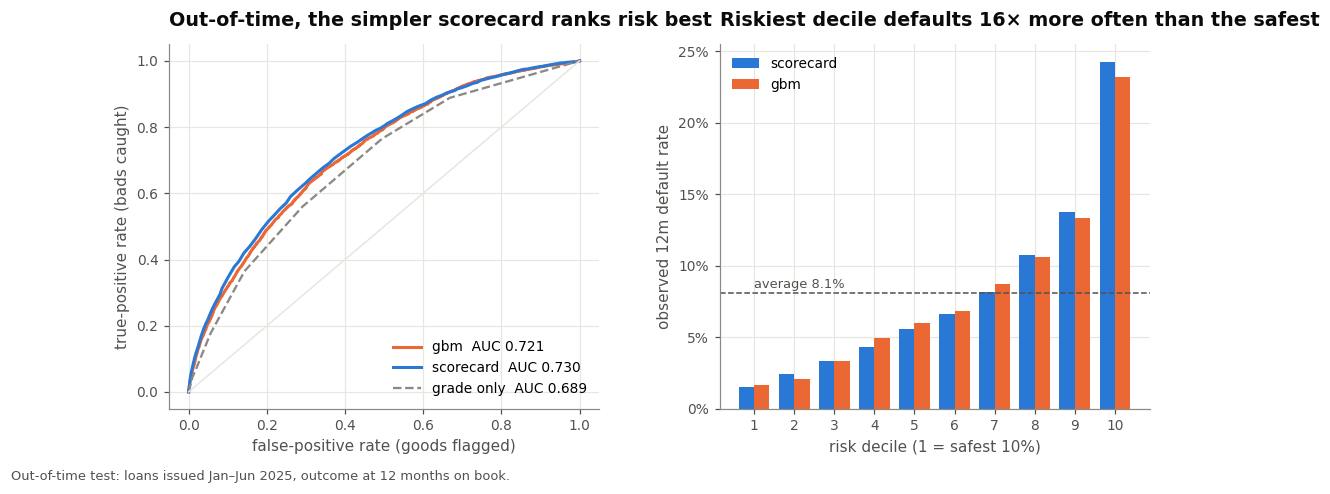

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw=dict(wspace=.28))
for k, col in [("gbm", C["orange"]), ("scorecard", C["blue"]), ("grade only", C["muted"])]:
    fpr, tpr, _ = roc_curve(te.y, S["test"][k])
    a1.plot(fpr, tpr, color=col, lw=2 if k != "grade only" else 1.5, ls="-" if k != "grade only" else "--",
            label=f"{k}  AUC {roc_auc_score(te.y, S['test'][k]):.3f}")
a1.plot([0, 1], [0, 1], color=C["grid"], lw=1)
a1.set_xlabel("false-positive rate (goods flagged)")
a1.set_ylabel("true-positive rate (bads caught)")
a1.legend(loc="lower right")
a1.set_title("Out-of-time, the simpler scorecard ranks risk best")
dec = pd.DataFrame({"y": te.y.values, "scorecard": S["test"]["scorecard"], "gbm": S["test"]["gbm"]})
w = .38
for j, (k, col) in enumerate([("scorecard", C["blue"]), ("gbm", C["orange"])]):
    dec[k + "_dec"] = pd.qcut(dec[k].rank(method="first"), 10, labels=False) + 1
    r = dec.groupby(k + "_dec").y.mean()
    a2.bar(r.index + (j - .5) * w, r.values, width=w, color=col, label=k)
a2.axhline(te.y.mean(), color=C["ink2"], lw=1, ls="--")
a2.text(1, te.y.mean() + .004, f"average {te.y.mean():.1%}", fontsize=8.5, color=C["ink2"])
a2.set_xticks(range(1, 11))
a2.set_xlabel("risk decile (1 = safest 10%)")
a2.yaxis.set_major_formatter(pct)
a2.set_ylabel("observed 12m default rate")
a2.legend(loc="upper left")
r_sc = dec.groupby("scorecard_dec").y.mean()
a2.set_title(f"Riskiest decile defaults {r_sc.iloc[-1] / r_sc.iloc[0]:.0f}× more often than the safest")
save(fig, "05_discrimination_oot", note="Out-of-time test: loans issued Jan–Jun 2025, outcome at 12 months on book.")
plt.show()

## 8 · Calibration: a PD is a promise

The profit rule multiplies probabilities by euros, so a model that ranks well but says "4 %" when the
truth is "8 %" will approve the wrong loans. Both models are recalibrated with **isotonic regression
fitted on the calibration window** and then checked on the untouched test window.

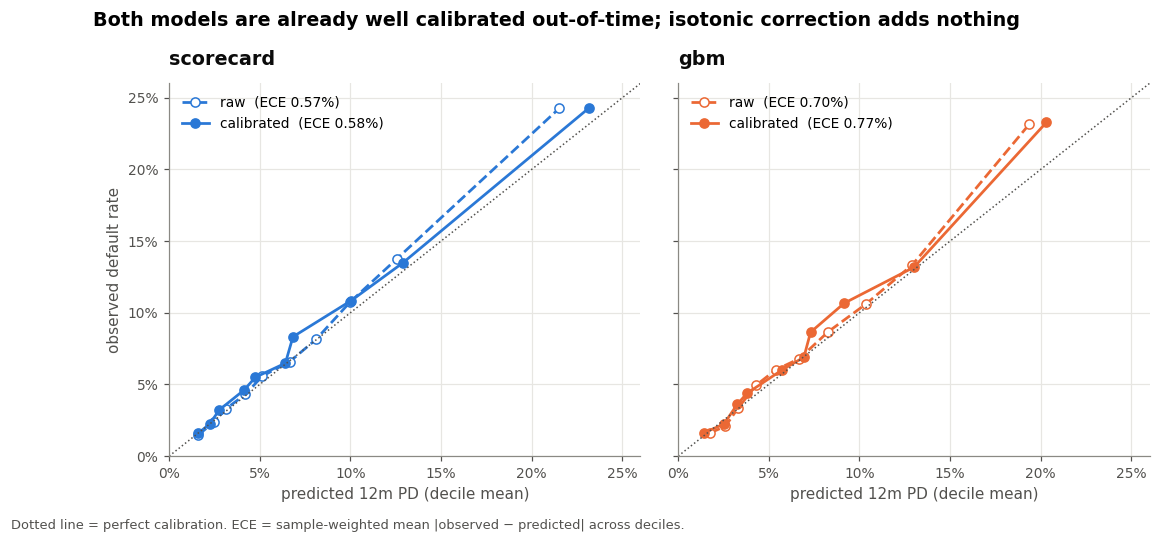

model,stage,ECE,mean_pd,observed,Brier
scorecard,raw,0.574%,7.54%,8.06%,0.0693
scorecard,calibrated,0.576%,7.48%,8.06%,0.0693
gbm,raw,0.697%,7.50%,8.06%,0.0699
gbm,calibrated,0.771%,7.35%,8.06%,0.0699


In [19]:
from sklearn.isotonic import IsotonicRegression
iso = {k: IsotonicRegression(out_of_bounds="clip", y_min=1e-4).fit(S["valid"][k], va.y) for k in ("scorecard", "gbm")}
P = {w_: {k: iso[k].predict(S[w_][k]) for k in ("scorecard", "gbm")} for w_ in ("train", "valid", "test", "live")}

def ece(y, p, bins=10):
    b = pd.qcut(pd.Series(p).rank(method="first"), bins, labels=False)
    t = pd.DataFrame({"y": np.asarray(y), "p": p, "b": b}).groupby("b").agg(y=("y", "mean"), p=("p", "mean"), n=("y", "size"))
    return float(np.sum(t.n * (t.y - t.p).abs()) / t.n.sum()), t

cal_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True, gridspec_kw=dict(wspace=.08))
for ax, (k, col) in zip(axes, [("scorecard", C["blue"]), ("gbm", C["orange"])]):
    for stage, p, style in [("raw", S["test"][k], dict(ls="--", marker="o", mfc="white")),
                            ("calibrated", P["test"][k], dict(ls="-", marker="o"))]:
        e, t = ece(te.y, p)
        cal_rows.append(dict(model=k, stage=stage, ECE=e, mean_pd=np.mean(p), observed=te.y.mean(), Brier=brier_score_loss(te.y, p)))
        ax.plot(t.p, t.y, color=col, ms=6, lw=1.8, label=f"{stage}  (ECE {e:.2%})", **style)
    ax.plot([0, .3], [0, .3], color=C["ink2"], lw=1, ls=":")
    ax.set_xlim(0, .26); ax.set_ylim(0, .26)
    ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
    ax.set_xlabel("predicted 12m PD (decile mean)")
    ax.set_title(k)
    ax.legend(loc="upper left")
axes[0].set_ylabel("observed default rate")
fig.suptitle("Both models are already well calibrated out-of-time; isotonic correction adds nothing", x=0.065, ha="left",
             fontsize=12.5, fontweight="semibold", y=1.03)
save(fig, "06_calibration_oot", note="Dotted line = perfect calibration. ECE = sample-weighted mean |observed − predicted| across deciles.")
plt.show()
pd.DataFrame(cal_rows).style.format({"ECE": "{:.3%}", "mean_pd": "{:.2%}", "observed": "{:.2%}", "Brier": "{:.4f}"}).hide(axis="index")

### Decision: the scorecard is the champion

| | Scorecard | Gradient boosting |
|---|---|---|
| Out-of-time AUC / Gini | **0.730 / 0.460** | 0.721 / 0.442 |
| Calibration window log-loss | **0.2479** | 0.2485 (best of 12 configurations) |
| Calibration out-of-time (ECE) | **0.57 pp** | 0.70 pp |
| Profit at its own optimum (test) | **€4.0M** | €3.9M |
| Reason codes | exact, from points | needs SHAP plus a translation layer |
| Monotone & auditable | by construction | constraints on two features only |

I expected gradient boosting to win. It did not. The paired bootstrap puts the AUC gap at **−0.009
(95 % CI −0.012 to −0.007)**, in favour of the scorecard, and even the most heavily regularised boosting
model cannot close it. The reason is the data. With a handful of application fields and a portfolio
whose product mix changes quickly, the coarse, monotone bins of a scorecard generalise better than
learned interactions, which partly fit the training period. **Complexity has to earn its place, and here
it does not.**

Isotonic recalibration did not improve either model (the scorecard is calibrated by construction), so
the policy uses the scorecard's own PD. The remaining gap (7.5 % predicted vs 8.1 % observed on the
test window) is a *level* shift between periods. It is covered by the PD stress test in §11 and the
monitoring plan.

In [20]:
CHAMP = "scorecard"
for w_, x_ in [("train", tr), ("valid", va), ("test", te), ("live", live)]:
    x_["pd"] = S[w_][CHAMP]
    x_["score"] = sc.score(x_).values
for x_ in (va, te):
    e_ = ue.loc[x_.term_bucket]
    x_["gain_ratio"], x_["loss_ratio"] = e_.gain.values, e_.loss.values
    x_["G"], x_["L"] = x_.issued_amount * x_.gain_ratio, x_.issued_amount * x_.loss_ratio
    x_["profit_if_approved"] = np.where(x_.y == 0, x_.G, -x_.L)   # realised, using the actual 12m outcome
    x_["ev_approve"] = (1 - x_.pd) * x_.G - x_.pd * x_.L           # expected, using only the model
print(f"Test window: {len(te):,} loans, €{te.issued_amount.sum()/1e6:.1f}M lent")
print(f"Approve-everything (status quo) realised profit: {eur(te.profit_if_approved.sum())}  "
      f"= {te.profit_if_approved.sum()/te.issued_amount.sum():.2%} of principal")
print(f"Loans with negative realised value: {(te.profit_if_approved < 0).mean():.1%} (all of them 12m defaults)")

Test window: 81,464 loans, €154.6M lent
Approve-everything (status quo) realised profit: €2.0M  = 1.29% of principal
Loans with negative realised value: 8.1% (all of them 12m defaults)


## 9 · The profit curve: where to draw the line

Sort applicants from safest to riskiest, approve the safest *x %*, and add up the euros each approved
loan actually made or lost on the test window. Every point on the curve is real loans, real
outcomes, and measured unit economics. The cut-off is **chosen on the calibration window** and only
*evaluated* on the test window. A cut-off picked on the test data would flatter the result.

In [21]:
def curve(x, score_col, steps=101):
    order = np.argsort(x[score_col].values, kind="stable")
    prof = x.profit_if_approved.values[order].cumsum()
    n = len(x)
    rates = np.linspace(0.01, 1, steps)
    idx = (rates * n).astype(int) - 1
    return pd.DataFrame({"approval_rate": rates, "profit": prof[idx],
                         "bad_rate": x.y.values[order].cumsum()[idx] / (idx + 1),
                         "cutoff": x[score_col].values[order][idx]})

for x_ in (va, te):
    x_["pd_gbm"] = S["valid" if x_ is va else "test"]["gbm"]
    x_["grade_plus"] = x_.rating_rank + RNG.uniform(0, .01, len(x_))  # grade-only rule, ties broken randomly
cv_va = curve(va, "pd")
best_va = cv_va.loc[cv_va.profit.idxmax()]
PD_CUTOFF = float(best_va.cutoff)
SCORE_CUTOFF = int(np.ceil(sc.offset + sc.factor * np.log((1 - PD_CUTOFF) / PD_CUTOFF)))
print(f"profit-optimal single cut-off (calibration window): PD ≤ {PD_CUTOFF:.2%}  ⇔  score ≥ {SCORE_CUTOFF}")
cv = {k: curve(te, c) for k, c in [("scorecard", "pd"), ("gbm", "pd_gbm"), ("grade rule", "grade_plus")]}

# bootstrap the test window to see how flat the optimum is
boot_opt = []
for _ in range(200):
    i = RNG.integers(0, len(te), len(te))
    b = curve(te.iloc[i], "pd")
    boot_opt.append(b.approval_rate[b.profit.idxmax()])
lo, hi = np.percentile(boot_opt, [5, 95])

status_quo = te.profit_if_approved.sum()
cut_rule = te.pd <= PD_CUTOFF
summary = {"approve all (status quo)": (1.0, status_quo, te.y.mean())}
summary[f"single PD cut-off ≤ {PD_CUTOFF:.1%} (set on calibration window)"] = (
    cut_rule.mean(), te.profit_if_approved[cut_rule].sum(), te.y[cut_rule].mean())
ev_rule = te.ev_approve > 0
summary["term-aware rule: approve if expected € > 0"] = (ev_rule.mean(), te.profit_if_approved[ev_rule].sum(), te.y[ev_rule].mean())
for k in cv:
    r = cv[k].loc[cv[k].profit.idxmax()]
    summary[f"hindsight optimum on test ({k}), for reference"] = (r.approval_rate, r.profit, r.bad_rate)
pol = pd.DataFrame(summary, index=["approval_rate", "profit", "bad_rate"]).T
pol["uplift_vs_status_quo"] = pol.profit - status_quo
print(f"optimal approval rate on test, 90% bootstrap band: {lo:.0%} – {hi:.0%}")
pol.style.format({"approval_rate": "{:.1%}", "profit": eur, "bad_rate": "{:.2%}", "uplift_vs_status_quo": eur})

profit-optimal single cut-off (calibration window): PD ≤ 11.15%  ⇔  score ≥ 547
optimal approval rate on test, 90% bootstrap band: 67% – 78%


,approval_rate,profit,bad_rate,uplift_vs_status_quo
approve all (status quo),100.0%,€2.0M,8.06%,€0
single PD cut-off ≤ 11.2% (set on calibration window),80.6%,€3.8M,5.38%,€1.8M
term-aware rule: approve if expected € > 0,75.2%,€4.1M,4.96%,€2.1M
"hindsight optimum on test (scorecard), for reference",77.2%,€4.0M,5.07%,€2.0M
"hindsight optimum on test (gbm), for reference",75.2%,€3.9M,5.11%,€1.9M
"hindsight optimum on test (grade rule), for reference",72.3%,€3.2M,5.34%,€1.2M


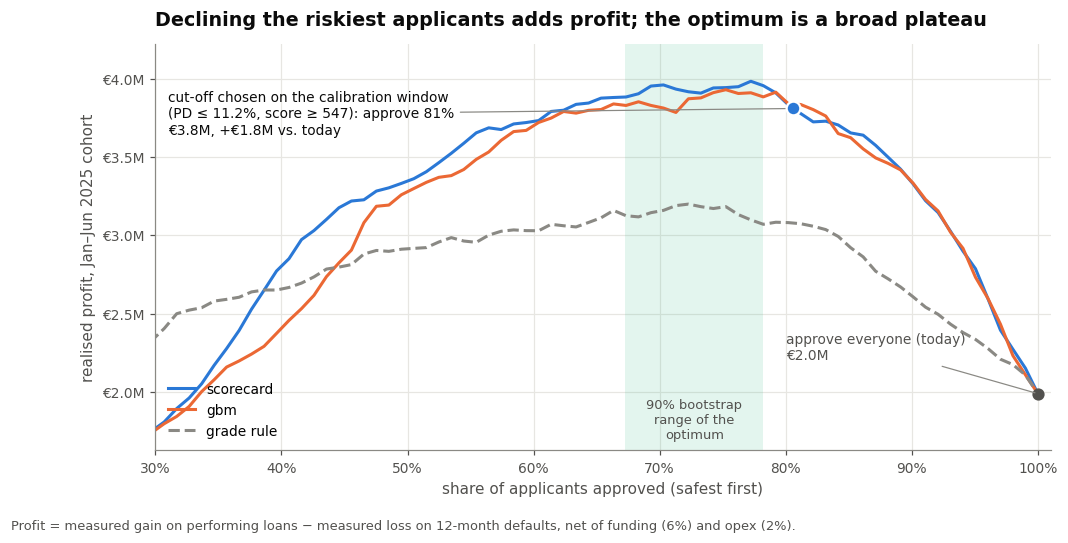

In [22]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.axvspan(lo, hi, color=C["aqua"], alpha=.12, lw=0)
ax.text((lo + hi) / 2, .03, "90% bootstrap\nrange of the\noptimum", transform=ax.get_xaxis_transform(),
        ha="center", fontsize=8.5, color=C["ink2"])
for k, col, ls in [("scorecard", C["blue"], "-"), ("gbm", C["orange"], "-"), ("grade rule", C["muted"], "--")]:
    ax.plot(cv[k].approval_rate, cv[k].profit, color=col, ls=ls, label=k)
ar, pr = pol.iloc[1].approval_rate, pol.iloc[1].profit
ax.plot([ar], [pr], "o", color=C["blue"], ms=9, mec="white", mew=1.5, zorder=5)
ax.annotate(f"cut-off chosen on the calibration window\n(PD ≤ {PD_CUTOFF:.1%}, score ≥ {SCORE_CUTOFF}): approve {ar:.0%}\n{eur(pr)}, +{eur(pr - status_quo)} vs. today", xy=(ar, pr),
            xytext=(.31, cv["scorecard"].profit.max() * .985), fontsize=9, color=C["ink"], va="top",
            arrowprops=dict(arrowstyle="-", color=C["muted"], lw=.8))
ax.plot([1], [status_quo], "o", color=C["ink2"], ms=7)
ax.annotate(f"approve everyone (today)\n{eur(status_quo)}", xy=(1, status_quo), xytext=(.80, status_quo + .12 * (pr - status_quo)),
            fontsize=9, color=C["ink2"], arrowprops=dict(arrowstyle="-", color=C["muted"], lw=.8))
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(eur))
ax.set_xlabel("share of applicants approved (safest first)")
ax.set_ylabel("realised profit, Jan–Jun 2025 cohort")
ax.set_xlim(.3, 1.01)
ax.set_ylim(min(cv["scorecard"].profit[cv["scorecard"].approval_rate >= .3].min(), status_quo) * .9, cv["scorecard"].profit.max() * 1.06)
ax.legend(loc="lower left")
ax.set_title("Declining the riskiest applicants adds profit; the optimum is a broad plateau")
save(fig, "07_profit_curve", note="Profit = measured gain on performing loans − measured loss on 12-month defaults, net of funding (6%) and opex (2%).")
plt.show()

**What the curve says**

* **Approving everyone earns €2.0M** on €155M lent (1.3 %). The defaults eat most of the margin.
* The profit-optimal single cut-off, **chosen on the calibration window**, is **PD ≤ 11.2 % (score ≥ 547)**.
  On the unseen test window it approves 81 % of applicants and earns **€3.8M**, close to the
  hindsight-best €4.0M.
* The **term-aware rule** (approve when expected € > 0, using each loan's own break-even) has *no tuned
  threshold at all*, and earns **€4.1M**. It beats even the hindsight-optimal single cut-off, because the
  break-even PD differs by term (§4).
* The scorecard curve sits above gradient boosting almost everywhere, and well above a pure grade rule
  (€3.2M). The extra features are worth about **€0.8M per half-year** over using the grade alone.
* The optimum is a plateau. In 90 % of bootstrap resamples the best approval rate falls between
  **67 % and 78 %**. Precision about the exact cut-off is worth little; the size of that flat region is
  what makes a refer band sensible.

## 10 · Approve, Refer or Decline: adding a manual-review band

Near the break-even point the model is close to a coin-flip *in euros*: approving or declining is
worth almost the same. That is exactly where a human underwriter adds value. They can check bank
statements, call the employer, or ask for a co-signer. Reviews cost money, so referral must be
justified by the numbers too.

For every applicant, compare three expected values:

| Action | Expected value |
|---|---|
| **Approve** | `(1 − PD)·G − PD·L` |
| **Refer** | `(1 − PD)·(1 − f)·G − PD·(1 − c)·L − review cost`: the reviewer stops a share **c** of the bads but also wrongly stops a share **f** of the goods |
| **Decline** | `0` |

…and take the largest. With **c = 35 %**, **f = 5 %** and **€20 per review** (conservative assumptions for
a desk check, tested in §11), a refer band appears *automatically* around the break-even point. It is
widest for large loans, where a review protects the most money.

In [23]:
def apply_policy(x, params, cap=None):
    e_ = cr.unit_economics(econ, params).loc[x.term_bucket]
    act, ev_a, ev_r = cr.decide(x.pd.values, x.issued_amount.values, e_.gain.values, e_.loss.values, params)
    act = act.copy()
    if cap is not None and (act == "REFER").mean() > cap:  # underwriting capacity: keep the most valuable referrals
        gain_r = np.where(act == "REFER", ev_r - np.maximum(ev_a, 0), -np.inf)
        keep = np.argsort(-gain_r)[: int(cap * len(x))]
        fallback = np.where(ev_a > 0, "APPROVE", "DECLINE")
        mask = (act == "REFER")
        mask[keep] = False
        act[mask] = fallback[mask]
    G, L = x.issued_amount.values * e_.gain.values, x.issued_amount.values * e_.loss.values
    y_ = x.y.values
    p = cr.DEFAULT_PARAMS | params
    realised = np.select([act == "APPROVE", act == "REFER"],
                         [np.where(y_ == 0, G, -L),
                          np.where(y_ == 0, (1 - p["review_false_decline"]) * G, -(1 - p["review_catch"]) * L) - p["review_cost"]], 0.0)
    return act, realised

REFER_CAP = 0.08  # assume the underwriting team can look at up to 8% of applications
te["action"], te["policy_profit"] = apply_policy(te, PARAMS, cap=REFER_CAP)
va["action"], va["policy_profit"] = apply_policy(va, PARAMS, cap=REFER_CAP)
mix = te.groupby("action").agg(applications=("y", "size"), default_rate=("y", "mean"),
                               avg_amount=("issued_amount", "mean"), realised_profit=("policy_profit", "sum"))
mix["share"] = mix.applications / len(te)
mix = mix.reindex(["APPROVE", "REFER", "DECLINE"])
three_way = te.policy_profit.sum()
pol.loc["approve / refer / decline (final policy)"] = [(te.action == "APPROVE").mean(), three_way,
                                                       te.y[te.action == "APPROVE"].mean(), three_way - status_quo]
print(f"Final policy realised profit on test: {eur(three_way)} → +{eur(three_way - status_quo)} vs. status quo "
      f"(+{(three_way - status_quo) / abs(status_quo):.0%})")
display(pol.style.format({"approval_rate": "{:.1%}", "profit": eur, "bad_rate": "{:.2%}", "uplift_vs_status_quo": eur}))
mix.style.format({"applications": "{:,.0f}", "default_rate": "{:.1%}", "avg_amount": "€{:,.0f}", "realised_profit": eur, "share": "{:.1%}"})

Final policy realised profit on test: €4.7M → +€2.7M vs. status quo (+137%)


,approval_rate,profit,bad_rate,uplift_vs_status_quo
approve all (status quo),100.0%,€2.0M,8.06%,€0
single PD cut-off ≤ 11.2% (set on calibration window),80.6%,€3.8M,5.38%,€1.8M
term-aware rule: approve if expected € > 0,75.2%,€4.1M,4.96%,€2.1M
"hindsight optimum on test (scorecard), for reference",77.2%,€4.0M,5.07%,€2.0M
"hindsight optimum on test (gbm), for reference",75.2%,€3.9M,5.11%,€1.9M
"hindsight optimum on test (grade rule), for reference",72.3%,€3.2M,5.34%,€1.2M
approve / refer / decline (final policy),69.6%,€4.7M,4.70%,€2.7M


,applications,default_rate,avg_amount,realised_profit,share
action,,,,,
APPROVE,"56,662",4.7%,"€1,188",€3.6M,69.6%
REFER,"6,517",9.1%,"€7,502",€1.1M,8.0%
DECLINE,"18,285",18.1%,"€2,100",€0,22.4%


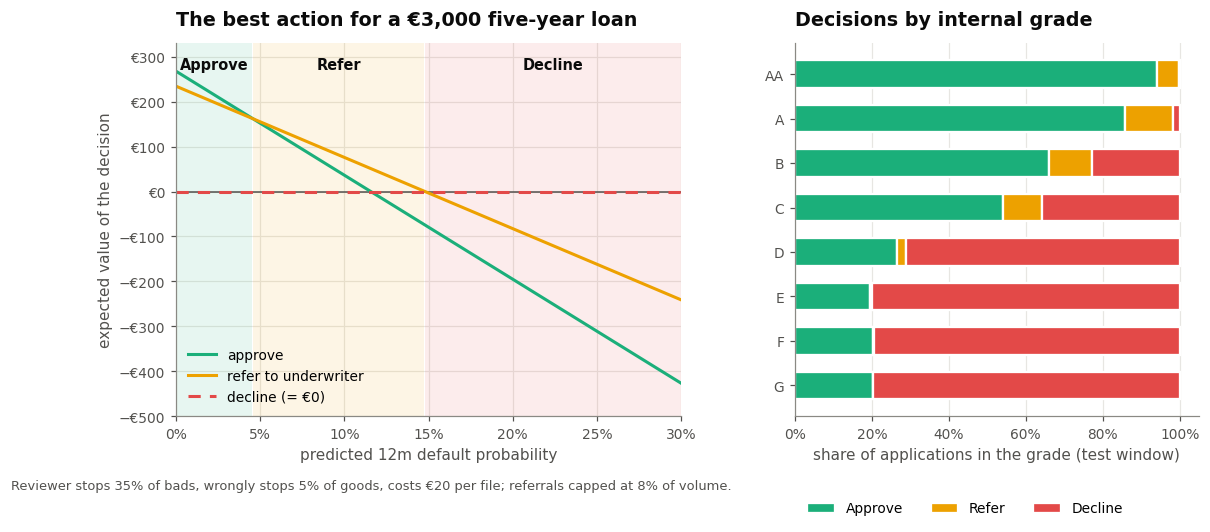

In [24]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw=dict(width_ratios=[1.25, 1], wspace=.25))
pdg = np.linspace(0, .3, 400)
e60 = ue.loc["49-60m"]
amt = 3000
act_g, eva, evr = cr.decide(pdg, np.full_like(pdg, amt), np.full_like(pdg, e60.gain), np.full_like(pdg, e60.loss), PARAMS)
a1.axhline(0, color=C["ink2"], lw=1)
a1.plot(pdg, eva, color=C["aqua"], label="approve")
a1.plot(pdg, evr, color=C["yellow"], label="refer to underwriter")
a1.plot(pdg, np.zeros_like(pdg), color=C["red"], lw=2, ls=(0, (4, 3)), label="decline (= €0)")
for lab, col in [("APPROVE", C["aqua"]), ("REFER", C["yellow"]), ("DECLINE", C["red"])]:
    xs = pdg[act_g == lab]
    if len(xs):
        a1.axvspan(xs.min(), xs.max(), color=col, alpha=.10, lw=0)
        a1.text(xs.mean(), .93, lab.title(), transform=a1.get_xaxis_transform(), ha="center", fontsize=9.5, fontweight="semibold", color=C["ink"])
a1.xaxis.set_major_formatter(pct)
a1.yaxis.set_major_formatter(mtick.FuncFormatter(eur))
a1.set_xlim(0, .3); a1.set_ylim(-500, 330)
a1.set_xlabel("predicted 12m default probability")
a1.set_ylabel("expected value of the decision")
a1.legend(loc="lower left")
a1.set_title(f"The best action for a €{amt:,} five-year loan")
gm = pd.crosstab(te.customer_risk_rating, te.action, normalize="index").reindex(cr.RATING_ORDER[:-1])[["APPROVE", "REFER", "DECLINE"]]
left = np.zeros(len(gm))
for lab, col in [("APPROVE", C["aqua"]), ("REFER", C["yellow"]), ("DECLINE", C["red"])]:
    a2.barh(gm.index, gm[lab], left=left, color=col, height=.62, label=lab.title(), edgecolor="white", linewidth=1.5)
    left += gm[lab].values
a2.invert_yaxis()
a2.xaxis.set_major_formatter(pct)
a2.set_xlabel("share of applications in the grade (test window)")
a2.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, -.3))
a2.set_title("Decisions by internal grade")
a2.grid(axis="y", visible=False)
save(fig, "08_policy_bands", note=f"Reviewer stops {PARAMS['review_catch']:.0%} of bads, wrongly stops {PARAMS['review_false_decline']:.0%} of goods, costs €{PARAMS['review_cost']:.0f} per file; referrals capped at {REFER_CAP:.0%} of volume.")
plt.show()

**Reading the policy**

* **Approve 69.6 %** of applicants (12-month default rate 4.7 %), **refer 8.0 %**, **decline 22.4 %** (default
  rate 18.1 %, so roughly 1 in 5 declined applicants would have defaulted within a year).
* Referrals are **large and borderline**: average €7.5k against €1.2k for approvals. A €20 desk check is
  only worth it when there is a lot of money at stake, and the rule finds that by itself.
* Of the **+€2.7M** uplift, **€2.1M comes from declining alone**, which depends only on the model and the
  measured economics. The remaining ≈ €0.6M depends on how effective underwriters are. That is an
  assumption, and the first thing I would measure in a pilot.
* By grade, the policy is not "decline grades E–G". It still approves about 20 % of them (mostly small
  1–4-year loans, the terms with the highest break-even PD), and it declines about a quarter of grade B applicants
  who take long loans with high loan-to-income ratios.

## 11 · Sensitivity: how wrong can the assumptions be before the policy breaks?

Every number in the economics is an estimate, and some are assumptions. Each one is moved to a
pessimistic and an optimistic value. Two questions are asked:

1. **How much does the profit of the policy change?** The policy is re-derived as if the new value
   were known.
2. **What is the regret?** This is the profit lost by keeping the *base* policy when the world turns
   out different. A small regret means it is safe to deploy now and refine later.

In [25]:
def evaluate(truth_params, decision_params, pd_mult=1.0):
    x = te.assign(pd=np.clip(te.pd * pd_mult, 0, 1))
    act, _ = apply_policy(x, decision_params, cap=REFER_CAP)
    # realised value of those actions under the 'true' economics
    e_ = cr.unit_economics(econ, truth_params).loc[x.term_bucket]
    G, L = x.issued_amount.values * e_.gain.values, x.issued_amount.values * e_.loss.values
    p = cr.DEFAULT_PARAMS | truth_params
    y_ = x.y.values
    val = np.select([act == "APPROVE", act == "REFER"],
                    [np.where(y_ == 0, G, -L),
                     np.where(y_ == 0, (1 - p["review_false_decline"]) * G, -(1 - p["review_catch"]) * L) - p["review_cost"]], 0.0)
    return val.sum(), (act != "DECLINE").mean(), (act == "REFER").mean()

base_val, base_ar, _ = evaluate(PARAMS, PARAMS)
SENS = [("cost of funds", "cost_of_funds", .04, .09), ("opex (% principal)", "opex", .01, .035),
        ("loss on default (× measured)", "lgd_multiplier", .85, 1.20), ("return on performing loan (× measured)", "gain_multiplier", .80, 1.15),
        ("review cost (€)", "review_cost", 10, 40), ("reviewer catch rate", "review_catch", .20, .50)]
rows = []
for label, k, low, high in SENS:
    for side, v in (("low", low), ("high", high)):
        truth = PARAMS | {k: v}
        opt_val, opt_ar, opt_ref = evaluate(truth, truth)
        kept_val, _, _ = evaluate(truth, PARAMS)
        sq = (np.where(te.y == 0, te.issued_amount * cr.unit_economics(econ, truth).loc[te.term_bucket].gain.values,
                       -te.issued_amount * cr.unit_economics(econ, truth).loc[te.term_bucket].loss.values)).sum()
        rows.append(dict(assumption=label, value=v, side=side, approval_rate=opt_ar, refer_rate=opt_ref,
                         policy_profit=opt_val, regret_if_base_policy_kept=opt_val - kept_val, status_quo_profit=sq,
                         uplift_vs_status_quo=opt_val - sq))
sens = pd.DataFrame(rows)
sens.style.format({"approval_rate": "{:.1%}", "refer_rate": "{:.1%}", "policy_profit": eur, "regret_if_base_policy_kept": eur,
                   "status_quo_profit": eur, "uplift_vs_status_quo": eur}).hide(axis="index")

assumption,value,side,approval_rate,refer_rate,policy_profit,regret_if_base_policy_kept,status_quo_profit,uplift_vs_status_quo
cost of funds,0.040000,low,91.9%,8.0%,€9.3M,€439k,€7.7M,€1.6M
cost of funds,0.090000,high,30.0%,4.0%,€1.3M,€2.8M,−€6.6M,€7.9M
opex (% principal),0.010000,low,83.7%,8.0%,€5.8M,−€18k,€3.5M,€2.3M
opex (% principal),0.035000,high,64.1%,8.0%,€3.2M,€155k,−€328k,€3.5M
loss on default (× measured),0.850000,low,84.4%,8.0%,€5.3M,−€13k,€3.4M,€1.9M
loss on default (× measured),1.200000,high,69.4%,8.0%,€4.0M,€109k,€102k,€3.9M
return on performing loan (× measured),0.800000,low,67.8%,8.0%,€3.1M,€134k,−€296k,€3.4M
return on performing loan (× measured),1.150000,high,83.7%,8.0%,€6.0M,−€12k,€3.7M,€2.3M
review cost (€),10.000000,low,77.6%,8.0%,€4.8M,€0,€2.0M,€2.8M
review cost (€),40.000000,high,77.6%,8.0%,€4.6M,€2k,€2.0M,€2.6M


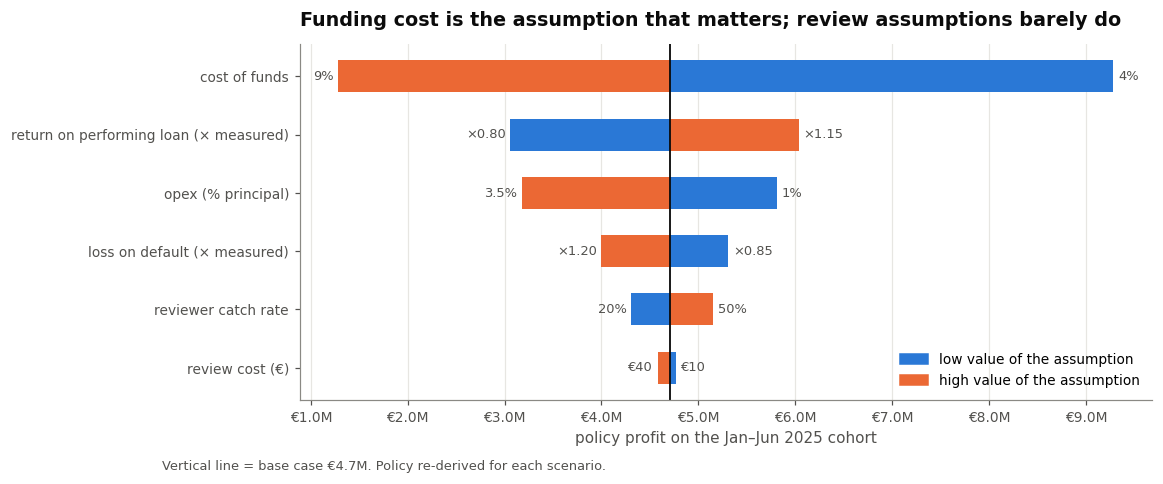

In [26]:
t = sens.pivot(index="assumption", columns="side", values="policy_profit")
t["span"] = (t.high - t.low).abs()
t = t.sort_values("span")
lab_vals = {l: (lo_, hi_) for l, _, lo_, hi_ in SENS}
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (a_, r) in enumerate(t.iterrows()):
    for side, col in (("low", C["blue"]), ("high", C["orange"])):  # colour = value of the assumption, not good/bad
        v = r[side]
        ax.barh(i, v - base_val, left=base_val, color=col, height=.55)
    lo_, hi_ = lab_vals[a_]
    fmt = (lambda z: f"×{z:.2f}") if "×" in a_ else ((lambda z: f"€{z:.0f}") if "€" in a_ else (lambda z: f"{z:.1%}".replace(".0%", "%")))
    ax.text(min(r.low, r.high) - abs(base_val) * .01, i, fmt(lo_ if r.low < r.high else hi_), va="center", ha="right", fontsize=8.5, color=C["ink2"])
    ax.text(max(r.low, r.high) + abs(base_val) * .01, i, fmt(hi_ if r.low < r.high else lo_), va="center", ha="left", fontsize=8.5, color=C["ink2"])
ax.axvline(base_val, color=C["ink"], lw=1.2)
ax.set_yticks(range(len(t)), t.index)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(eur))
ax.set_xlabel("policy profit on the Jan–Jun 2025 cohort")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C["blue"], label="low value of the assumption"), Patch(color=C["orange"], label="high value of the assumption")],
          loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title("Funding cost is the assumption that matters; review assumptions barely do")
save(fig, "09_sensitivity_tornado", note=f"Vertical line = base case {eur(base_val)}. Policy re-derived for each scenario.")
plt.show()

**Stress-testing the model itself.** The 2025 cohort defaulted slightly more than the model expected.
What if defaults in a downturn are 25–50 % higher across the board? The policy below is re-derived
with inflated PDs, and the outcome is simulated by inflating defaults the same way.

In [27]:
stress = []
for mult in (1.0, 1.1, 1.25, 1.5):
    x = te.copy()
    x["pd"] = np.clip(te.pd * mult, 0, 1)
    act, _ = apply_policy(x, PARAMS, cap=REFER_CAP)
    e_ = ue.loc[x.term_bucket]
    G, L = x.issued_amount.values * e_.gain.values, x.issued_amount.values * e_.loss.values
    # expected value under the stressed PD (labels can't be stressed directly)
    ev_pol = np.select([act == "APPROVE", act == "REFER"],
                       [(1 - x.pd) * G - x.pd * L,
                        (1 - x.pd) * (1 - PARAMS["review_false_decline"]) * G - x.pd * (1 - PARAMS["review_catch"]) * L - PARAMS["review_cost"]], 0).sum()
    ev_all = ((1 - x.pd) * G - x.pd * L).sum()
    stress.append(dict(pd_multiplier=mult, approval_rate=(act == "APPROVE").mean(), refer_rate=(act == "REFER").mean(),
                       decline_rate=(act == "DECLINE").mean(), expected_profit_policy=ev_pol, expected_profit_approve_all=ev_all,
                       value_of_policy=ev_pol - ev_all))
stress = pd.DataFrame(stress)
stress.style.format({"approval_rate": "{:.1%}", "refer_rate": "{:.1%}", "decline_rate": "{:.1%}", "expected_profit_policy": eur,
                     "expected_profit_approve_all": eur, "value_of_policy": eur}).hide(axis="index")

pd_multiplier,approval_rate,refer_rate,decline_rate,expected_profit_policy,expected_profit_approve_all,value_of_policy
1.000000,69.6%,8.0%,22.4%,€5.2M,€3.2M,€2.0M
1.100000,64.6%,8.0%,27.4%,€4.8M,€2.3M,€2.5M
1.250000,58.9%,8.0%,33.1%,€4.3M,€855k,€3.4M
1.500000,49.2%,8.0%,42.8%,€3.6M,−€1.5M,€5.1M


**What the sensitivity analysis says**

* **Cost of funds dominates.** At 4 % the policy earns €9.3M; at 9 % it earns €1.3M and approves only
  30 %. If funding really cost 9 % and the base policy were kept, about €2.8M would be left on the
  table. **This is the one input to agree with Treasury before go-live, and to re-derive monthly.**
* Every other assumption (opex, loss severity, return on performing loans, review cost and
  effectiveness) leaves regret **below €0.16M**. The policy is robust to them. Small negative "regret"
  values are sampling noise (a re-derived policy is optimal in expectation, not on every sample).
* **The policy is insurance.** If defaults run 50 % above the model's expectation, approving everyone
  *loses* €1.5M, while the policy still earns €3.6M. Its value rises from €2.0M to €5.1M exactly when
  it is needed most.

## 12 · Reason codes: every decline must be explainable

Under EU consumer-credit rules (CCD2, Art. 18) and the GDPR right to an explanation of automated
decisions, a declined applicant is entitled to know *why*. The scorecard makes this exact rather than
approximate: for each characteristic, measure how many points the applicant lost compared with the
best possible attribute, and report the largest shortfalls. No surrogate model and no SHAP
approximation are needed. The explanation **is** the model.

In [28]:
max_pts = sc_table.groupby("feature").points.max().to_dict()
pts_te = sc.points(te)
rc = cr.reason_codes(pts_te, max_pts, k=3)
te = te.join(rc)
neg = te[te.action != "APPROVE"]
rc_dist = (neg.reason_1.map(cr.REASON_TEXT).value_counts(normalize=True).rename("share of declines & referrals")
           .to_frame())
rc_dist.style.format("{:.1%}")

,share of declines & referrals
reason_1,
Internal risk grade is weak,83.1%
Requested term is in a higher-risk range,12.6%
Market has elevated observed losses,4.3%


In [29]:
def show_value(f, row):
    return {"rating_rank": f"grade {row.customer_risk_rating}", "country": row.country,
            "initial_loan_duration": f"{row.initial_loan_duration:.0f}-month term",
            "loan_to_income": f"loan = {row.loan_to_income:.1f}× monthly income",
            "combined_income": f"income €{row.combined_income:,.0f}/month"}.get(f, f"{f}={row[f]}")

def explain(row):
    parts = []
    for i in (1, 2, 3):
        f = row[f"reason_{i}"]
        if f:
            parts.append(f"{i}. {cr.REASON_TEXT[f]}: {show_value(f, row)} (−{max_pts[f] - pts_te.loc[row.name, f]} pts)")
    return "\n".join(parts)

ex = te[te.action == "DECLINE"].sample(5, random_state=3)
ex_out = pd.DataFrame({
    "grade": ex.customer_risk_rating, "country": ex.country, "amount": ex.issued_amount.map("€{:,.0f}".format),
    "term": ex.initial_loan_duration, "income": ex.combined_income.map("€{:,.0f}".format),
    "score": ex.score, "PD": ex.pd.map("{:.1%}".format), "E[profit]": ex.ev_approve.map(eur),
    "top reasons": ex.apply(explain, axis=1)})
pd.set_option("display.max_colwidth", 400)
ex_out.style.set_properties(subset=["top reasons"], **{"white-space": "pre-wrap", "text-align": "left"}).hide(axis="index")

grade,country,amount,term,income,score,PD,E[profit],top reasons
E,Latvia,€432,60,€677,496,42.4%,−€103,1. Internal risk grade is weak: grade E (−47 pts) 2. Market has elevated observed losses: Latvia (−43 pts) 3. Requested term is in a higher-risk range: 60-month term (−22 pts)
E,Finland,€518,84,€796,528,19.5%,−€40,1. Internal risk grade is weak: grade E (−47 pts) 2. Requested term is in a higher-risk range: 84-month term (−22 pts) 3. Market has elevated observed losses: Finland (−11 pts)
E,Finland,€103,54,"€1,880",541,13.4%,−€1,1. Internal risk grade is weak: grade E (−47 pts) 2. Requested term is in a higher-risk range: 54-month term (−22 pts) 3. Market has elevated observed losses: Finland (−11 pts)
B,Estonia,"€2,126",96,"€1,303",547,11.2%,−€32,1. Internal risk grade is weak: grade B (−27 pts) 2. Requested term is in a higher-risk range: 96-month term (−22 pts) 3. Market has elevated observed losses: Estonia (−13 pts)
G,Estonia,€956,60,"€1,100",522,23.0%,−€84,1. Internal risk grade is weak: grade G (−53 pts) 2. Requested term is in a higher-risk range: 60-month term (−22 pts) 3. Market has elevated observed losses: Estonia (−13 pts)


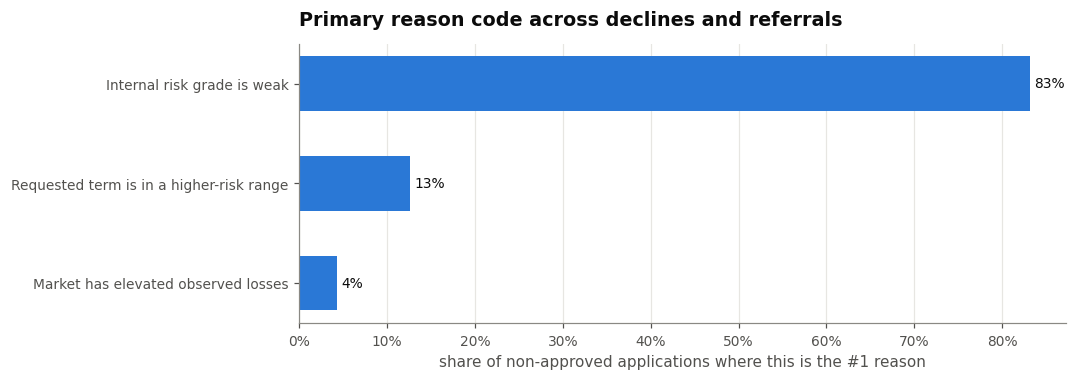

In [30]:
fig, ax = plt.subplots(figsize=(9, 3.3))
r_ = rc_dist.iloc[:, 0].sort_values()
ax.barh(r_.index, r_.values, color=C["blue"], height=.55)
for i, v in enumerate(r_.values):
    ax.text(v + .005, i, f"{v:.0%}", va="center", fontsize=9, color=C["ink"])
ax.xaxis.set_major_formatter(pct)
ax.grid(axis="y", visible=False)
ax.set_xlabel("share of non-approved applications where this is the #1 reason")
ax.set_title("Primary reason code across declines and referrals")
save(fig, "10_reason_codes")
plt.show()

## 13 · Drift: is the world the model learned still the world it is scoring?

The **Population Stability Index** compares today's distribution of each input, and of the score
itself, with the training window. Conventional reading: **< 0.10 stable**, **0.10–0.25 investigate**,
**> 0.25 act** (recalibrate or rebuild). Two comparisons are made: the test window (Jan–Jun 2025) and
the **live** population of the most recent 12 months, whose outcomes are not yet known.

score PSI by quarter: {'2024Q4': 0.083, '2025Q1': 0.106, '2025Q2': 0.175, '2025Q3': 0.221, '2025Q4': 0.1, '2026Q1': 0.03, '2026Q2': 0.032}


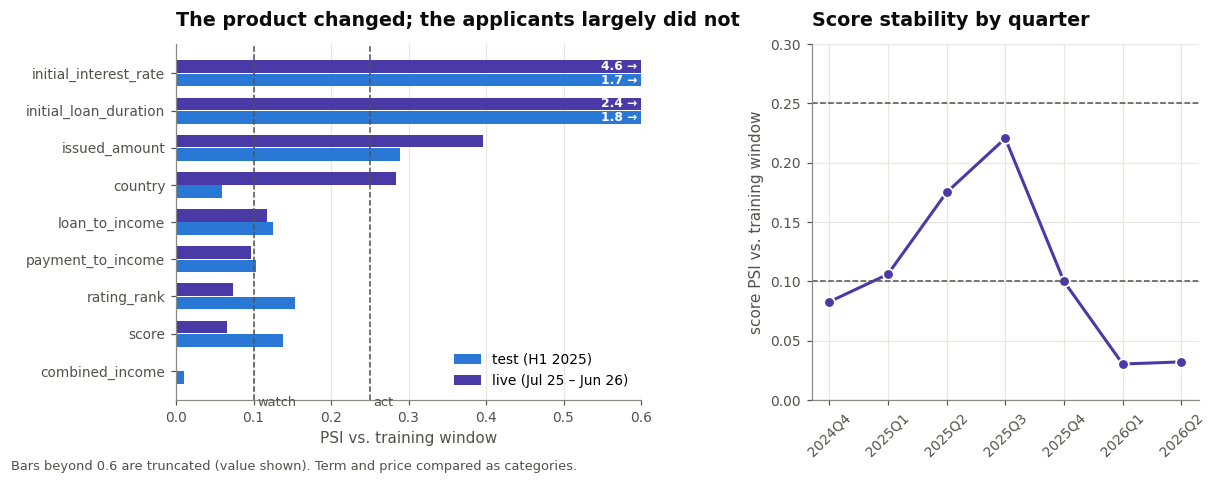

,psi_test,psi_live
feature,,
combined_income,0.010,0.002
score,0.138,0.066
rating_rank,0.154,0.073
payment_to_income,0.103,0.097
loan_to_income,0.126,0.117
country,0.060,0.284
issued_amount,0.289,0.396
initial_loan_duration,1.804,2.408
initial_interest_rate,1.745,4.633


In [31]:
drift_feats = sc.features + [f for f in ["issued_amount", "payment_to_income", "initial_interest_rate"] if f not in sc.features]
rows = []
# discrete inputs are compared as categories (quantile bins would split point masses arbitrarily)
as_cat = {"country": lambda x: x.country, "initial_loan_duration": lambda x: x.term_bucket,
          "initial_interest_rate": lambda x: (x.initial_interest_rate * 100).round().clip(upper=35)}
for f in drift_feats + ["score"]:
    get = as_cat.get(f, lambda x, f=f: x[f])
    cat = f in as_cat
    rows.append(dict(feature=f, psi_test=cr.psi(get(tr), get(te), categorical=cat), psi_live=cr.psi(get(tr), get(live), categorical=cat)))
psi_t = pd.DataFrame(rows).set_index("feature").sort_values("psi_live")

live["q"] = live.issued_at.dt.to_period("Q").astype(str)
qpsi = pd.Series({q: cr.psi(tr.score, g.score) for q, g in pd.concat([va.assign(q=va.issued_at.dt.to_period("Q").astype(str)),
                                                                     te.assign(q=te.issued_at.dt.to_period("Q").astype(str)), live]).groupby("q")})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.2, 1], wspace=.4))
yy = np.arange(len(psi_t))
a1.barh(yy - .18, psi_t.psi_test, height=.34, color=C["blue"], label="test (H1 2025)")
a1.barh(yy + .18, psi_t.psi_live, height=.34, color=C["violet"], label="live (Jul 25 – Jun 26)")
a1.set_yticks(yy, psi_t.index)
XMAX = .6
a1.set_xlim(0, XMAX)
for j_, col_ in ((-.18, "psi_test"), (.18, "psi_live")):
    for i_, v_ in enumerate(psi_t[col_]):
        if v_ > XMAX:
            a1.text(XMAX - .005, i_ + j_, f"{v_:.1f} →", va="center", ha="right", fontsize=8, color="white", fontweight="semibold")
for v_, lab_ in ((.10, "watch"), (.25, "act")):
    a1.axvline(v_, color=C["ink2"], lw=1, ls="--")
    a1.text(v_ + .005, -.95, lab_, fontsize=8.5, color=C["ink2"])
a1.set_xlabel("PSI vs. training window")
a1.legend(loc="lower right")
a1.grid(axis="y", visible=False)
a1.set_title("The product changed; the applicants largely did not")
a2.plot(range(len(qpsi)), qpsi.values, "o-", color=C["violet"], ms=7, mec="white", mew=1.2)
a2.axhline(.10, color=C["ink2"], lw=1, ls="--"); a2.axhline(.25, color=C["ink2"], lw=1, ls="--")
a2.set_xticks(range(len(qpsi)), qpsi.index, rotation=45)
a2.set_ylabel("score PSI vs. training window")
a2.set_ylim(0, max(.3, qpsi.max() * 1.15))
a2.set_title("Score stability by quarter")
save(fig, "11_drift_psi", note="Bars beyond 0.6 are truncated (value shown). Term and price compared as categories.")
plt.show()
print("score PSI by quarter:", qpsi.round(3).to_dict())
psi_t.style.format("{:.3f}")

In [32]:
live["pd"] = S["live"][CHAMP]
e_live = ue.loc[live.term_bucket]
live["ev_approve"] = (1 - live.pd) * live.issued_amount * e_live.gain.values - live.pd * live.issued_amount * e_live.loss.values
live_act, _ = cr.decide(live.pd.values, live.issued_amount.values, e_live.gain.values, e_live.loss.values, PARAMS)[0], None
cmp_ = pd.DataFrame({
    "train": [tr.issued_amount.median(), tr.initial_loan_duration.median(), (tr.country == "Finland").mean(), tr.pd.mean(), np.nan],
    "test": [te.issued_amount.median(), te.initial_loan_duration.median(), (te.country == "Finland").mean(), te.pd.mean(), (te.action == "DECLINE").mean()],
    "live": [live.issued_amount.median(), live.initial_loan_duration.median(), (live.country == "Finland").mean(), live.pd.mean(), (live_act == "DECLINE").mean()],
}, index=["median amount (€)", "median term (months)", "share Finland", "mean predicted PD", "decline rate under policy"])
cmp_.T.style.format({"median amount (€)": "€{:,.0f}", "median term (months)": "{:.0f}", "share Finland": "{:.1%}",
                     "mean predicted PD": "{:.2%}", "decline rate under policy": "{:.1%}"}, na_rep="–")

,median amount (€),median term (months),share Finland,mean predicted PD,decline rate under policy
train,"€1,036",60,69.0%,8.99%,–
test,€832,60,65.8%,7.54%,22.4%
live,€936,78,62.0%,8.05%,21.6%


**What the drift check says**

* **The score itself is stable on live data overall (PSI 0.07).** It drifted into the "investigate"
  zone in Q2–Q3 2025 (peak 0.22) and returned to ≈ 0.03 by 2026. That pattern is worth a monthly
  check, not a rebuild.
* **The product has moved.** In training, 3 % of loans were longer than 60 months. In 2025 it is 48 %,
  and in the live window 53 % (84- and 120-month loans). Prices collapsed to almost a single point
  (17.5 %). The term features are far beyond the "act" line, and the >60-month unit economics are
  measured on only 2,782 older loans.
* **Country mix is shifting (PSI 0.28)** as Denmark grows: a market that was almost absent from training.
* Encouragingly, calibration on >60-month loans held out-of-time (7.1 % predicted vs 7.2 % observed). So
  the immediate action is **not a rebuild**. Instead: (1) re-measure the economics of long-term loans
  as they season, and (2) put a launch override on Denmark (see §14).

## 14 · Segment checks: does the model work for everyone it scores?

A model can be well calibrated on average and still wrong for a whole market or product. For every
segment, the predicted PD is compared with the observed default rate on the test window, along with
the segment's ranking power and how the policy treats it. Segments where predictions miss by more
than ±20 % (n ≥ 500) are flagged.

In [33]:
te["amount_band"] = pd.cut(te.issued_amount, [0, 500, 1000, 2500, 5000, 1e9], labels=["≤€500", "€500–1k", "€1–2.5k", "€2.5–5k", ">€5k"]).astype(str)
seg_rows = []
for dim in ["country", "term_bucket", "amount_band", "customer_risk_rating"]:
    for k, g_ in te.groupby(dim):
        auc_ = roc_auc_score(g_.y, g_.pd) if g_.y.nunique() > 1 and len(g_) >= 300 else np.nan
        seg_rows.append(dict(dimension=dim, segment=k, loans=len(g_), observed=g_.y.mean(), predicted=g_.pd.mean(),
                             ratio=g_.pd.mean() / max(g_.y.mean(), 1e-9), AUC=auc_,
                             approve=(g_.action == "APPROVE").mean(), refer=(g_.action == "REFER").mean(),
                             decline=(g_.action == "DECLINE").mean(), profit_per_loan=g_.policy_profit.mean()))
seg = pd.DataFrame(seg_rows)
seg["flag"] = np.where((seg.loans >= 500) & ((seg.ratio < .8) | (seg.ratio > 1.2)), "⚠ check", "")
seg.style.format({"loans": "{:,.0f}", "observed": "{:.1%}", "predicted": "{:.1%}", "ratio": "{:.2f}", "AUC": "{:.3f}",
                  "approve": "{:.0%}", "refer": "{:.0%}", "decline": "{:.0%}", "profit_per_loan": eur}, na_rep="–").hide(axis="index")

dimension,segment,loans,observed,predicted,ratio,AUC,approve,refer,decline,profit_per_loan,flag
country,Denmark,756,39.0%,25.2%,0.65,0.605,15%,1%,84%,−€1,⚠ check
country,Estonia,"12,743",9.0%,9.2%,1.02,0.721,61%,6%,34%,€45,
country,Finland,"53,635",7.3%,6.8%,0.94,0.696,70%,9%,21%,€52,
country,Latvia,"2,329",29.9%,27.3%,0.91,0.618,12%,3%,85%,−€11,
country,Netherlands,"12,001",4.4%,4.0%,0.90,0.657,93%,6%,2%,€114,
term_bucket,13-24m,"7,549",5.6%,5.1%,0.92,0.707,96%,2%,2%,€54,
term_bucket,25-36m,"5,494",5.8%,6.0%,1.04,0.717,92%,3%,4%,€149,
term_bucket,37-48m,"3,818",7.2%,5.2%,0.73,0.695,97%,1%,2%,€214,⚠ check
term_bucket,49-60m,"16,953",14.0%,12.7%,0.90,0.723,47%,10%,43%,€45,
term_bucket,<=12m,"8,659",4.3%,3.5%,0.81,0.760,90%,0%,10%,€5,


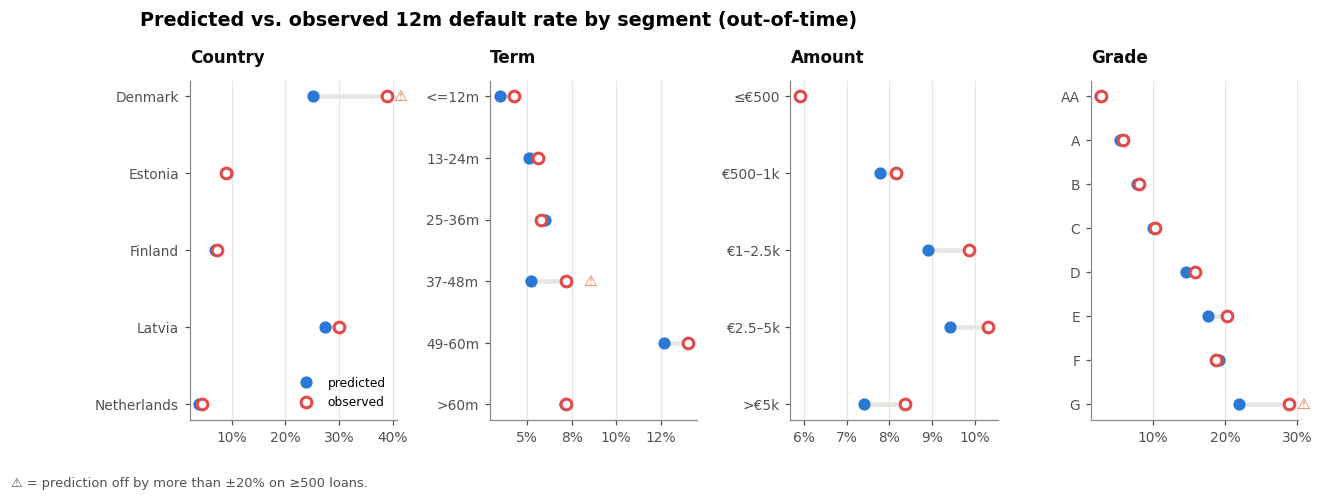

In [34]:
sp = seg[seg.loans >= 300].copy()
sp["label"] = sp.segment.astype(str)
dims = ["country", "term_bucket", "amount_band", "customer_risk_rating"]
titles = {"country": "Country", "term_bucket": "Term", "amount_band": "Amount", "customer_risk_rating": "Grade"}
fig, axes = plt.subplots(1, 4, figsize=(13, 4), gridspec_kw=dict(wspace=.45))
for ax, dim in zip(axes, dims):
    s_ = sp[sp.dimension == dim]
    order = {"customer_risk_rating": cr.RATING_ORDER, "term_bucket": cr.TERM_LABELS,
             "amount_band": ["≤€500", "€500–1k", "€1–2.5k", "€2.5–5k", ">€5k"]}.get(dim)
    if order:
        s_ = s_.set_index("label").reindex([g for g in order if g in set(s_.label)]).reset_index()
    yy = np.arange(len(s_))
    ax.hlines(yy, s_.predicted, s_.observed, color=C["grid"], lw=3)
    ax.plot(s_.predicted, yy, "o", color=C["blue"], ms=7, label="predicted")
    ax.plot(s_.observed, yy, "o", color=C["red"], ms=7, mfc="white", mew=2, label="observed")
    for i, (_, r) in enumerate(s_.iterrows()):
        if r.flag:
            ax.text(max(r.predicted, r.observed) + .01, i, "⚠", va="center", fontsize=10, color=C["orange"])
    ax.set_yticks(yy, s_.label)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(pct)
    ax.set_title(titles[dim], fontsize=11)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Predicted vs. observed 12m default rate by segment (out-of-time)", x=0.09, ha="left", fontsize=12.5, fontweight="semibold", y=1.04)
save(fig, "12_segment_calibration", note="⚠ = prediction off by more than ±20% on ≥500 loans.")
plt.show()

**What the segment checks say**

* **Calibration holds across the large segments.** Finland, Estonia, the Netherlands, every amount
  band and grades AA–F are all within ±13 %.
* **Denmark ⚠** is under-predicted (25 % vs 39 % observed). The scorecard never saw it during training
  and scores it as a generic "other" market. The policy already declines 84 % of Danish applicants, but
  the right fix is governance, not modelling: **refer all Danish applications, with a volume cap, until
  12 months of outcomes exist**, then add Denmark as its own attribute.
* **Grade G ⚠** is under-predicted (22 % vs 29 %), but the policy already declines 80 % of G, so the
  euro impact is small. 37–48-month loans are over-predicted, which makes the policy slightly
  conservative there.
* **Fairness note.** The data contains no protected attributes (age, gender), so a direct fairness
  audit is not possible. `country` is the borrower's market of residence, not nationality. It is
  legitimate (losses differ 7× between markets) but should be reviewed by compliance, as it is the
  feature closest to a protected characteristic.

In [35]:
# ---- persist everything the simulator and a future scoring service need --------------------------
policy = dict(
    model="WoE scorecard (logistic), monotone bins", pd_cutoff_single=PD_CUTOFF, refer_cap=REFER_CAP,
    params=PARAMS, unit_economics=econ.reset_index().to_dict("records"),
    windows=WIN, features=sc.features, reason_text=cr.REASON_TEXT, max_points=max_pts,
    test_metrics=perf.loc["scorecard"].to_dict(),
)
json.dump(policy, open(ART / "policy.json", "w"), indent=1, default=float)
keep = ["issued_at", "country", "customer_risk_rating", "issued_amount", "initial_loan_duration", "term_bucket",
        "combined_income", "loan_to_income", "score", "pd", "y", "reason_1", "reason_2", "reason_3"]
te[keep].to_csv(ART / "test_scored.csv.gz", index=False, compression="gzip")
live[["issued_at", "country", "customer_risk_rating", "issued_amount", "initial_loan_duration", "term_bucket", "combined_income", "loan_to_income", "score", "pd"]] \
    .to_csv(ART / "live_scored.csv.gz", index=False, compression="gzip")
tr[["score"] + sc.features].sample(20000, random_state=0).to_csv(ART / "train_reference.csv.gz", index=False, compression="gzip")
seg.to_csv(REP / "segment_checks.csv", index=False)
psi_t.to_csv(REP / "psi.csv")
sens.to_csv(REP / "sensitivity.csv", index=False)
pol.to_csv(REP / "policy_comparison.csv")
perf.to_csv(REP / "model_comparison.csv")
print("saved:", sorted(p.name for p in ART.iterdir()), sorted(p.name for p in REP.iterdir()))

saved: ['live_scored.csv.gz', 'policy.json', 'scorecard.json', 'scorecard_points.csv', 'test_scored.csv.gz', 'train_reference.csv.gz', 'unit_economics_raw.csv'] ['leakage_log.csv', 'model_comparison.csv', 'policy_comparison.csv', 'psi.csv', 'segment_checks.csv', 'sensitivity.csv']


## 15 · What I would do next

1. **Pilot before scaling.** Run the policy as a challenger on 10–20 % of traffic for 3–6 months. In the
   refer band, record what underwriters decide and why. That replaces the two reviewer assumptions
   (35 % catch / 5 % false decline) with measured values.
2. **Fix the selection bias.** All loans here were approved by the incumbent process, so this policy
   can only *tighten*. To learn whether some of today's declines are profitable, approve a small random
   sample (e.g. 1–2 % of near-miss declines) as a test-and-learn budget, or apply reject inference.
3. **Price for risk.** Grades AA–F pay the same price. A risk-based price would turn part of the 22 %
   declines into profitable approvals. That is a bigger lever than any model improvement.
4. **Monitoring pack (monthly):** score PSI and feature PSI (alert at 0.10 / 0.25), predicted vs
   observed default rate by vintage at 3/6/12 months on book, approval / refer / decline mix, refer
   outcomes, and the cost of funds feeding the policy.
5. **Re-measure the economics** of 84–120-month loans as they season, since they are now half the book.
6. **Richer data** (bureau, bank-transaction features) is the realistic route above AUC 0.73. The
   pipeline, policy and simulator here are ready to take a better PD without change.